# Детекция: от dense attention к обучаемым точкам выборки

В dense attention кандидат сравнивается со всеми позициями карты признаков. В deformable attention он предсказывает несколько точек, берёт в них признаки и уточняет бокс.

1. Состояние query, позиционный embedding и опорный бокс.
2. Билинейная интерполяция, обучаемые смещения и веса точек.
3. Использование предыдущего бокса для следующей выборки признаков.
4. Признаки нескольких разрешений при одинаковом числе точек.
5. Абляции, метрики, время и проверка на реальных изображениях.

Все реализации находятся в ноутбуке. Результаты запусков и рисунки сохранены.

[Запуск](../README.md) · [Пояснения и статьи](../ADDITIONAL_NOTES.md)

### Данные и размеры тензоров

Вход — RGB-изображение $192\times256$. Замороженный ResNet18 с ImageNet-весами выдаёт три карты. На каждом уровне обучаем отдельную проекцию $1\times1$ и GroupNorm:

| Уровень | Шаг сетки, пикселей | Выход ResNet | После проекции |
|---|---:|---|---|
| C3 | 8 | $B\times128\times24\times32$ | $B\times64\times24\times32$ |
| C4 | 16 | $B\times256\times12\times16$ | $B\times64\times12\times16$ |
| C5 | 32 | $B\times512\times6\times8$ | $B\times64\times6\times8$ |

$B$ — размер batch; $Q=32$ кандидата; $D=64$ канала состояния; $M=4$ attention heads, по $d=D/M=16$ каналов; $T=3$ слоя декодера. В sampling каждый head читает $K=6$ точек. Обозначение $F_\ell$ ниже относится к карте **после проекции**.

**Shapes:** 192 train / 64 validation, прямоугольники и эллипсы, один класс, 0–4 объекта. **COCO128/person:** отдельный опыт на 96 train / 32 validation с реальными изображениями. Изображения без объектов сохраняем: на них модель учится выдавать no-object.

Каждый вариант обучается 600 шагов с batch 8, AdamW, learning rate от $4\cdot10^{-4}$ до $4\cdot10^{-5}$ по cosine schedule, weight decay $10^{-4}$, clipping нормы градиента 0.5. Seeds: 41, 42, 43. Во всех опытах backbone заморожен; учатся проекции и декодер.

In [1]:
import contextlib
import copy
import hashlib
import inspect
import io
import json
import math
import random
import time
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from PIL import Image, ImageDraw
from scipy.optimize import linear_sum_assignment
from torchvision.models import resnet18
from torchvision.ops import generalized_box_iou, box_iou, box_convert
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
DATA = ROOT / 'data'
RUNS = ROOT / 'runs/detection60'
FIGURES = ROOT / 'figures'
for directory in (DATA, RUNS, FIGURES):
    directory.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(4)
DEVICE = torch.device('cpu')
IMAGE_SIZE = (192, 256)
SEEDS = [41, 42, 43]
TRAIN_STEPS = 600
BATCH_SIZE = 8
DIM, HEADS, QUERIES, LAYERS, POINTS = 64, 4, 32, 3, 6
COLORS = ['#1967d2', '#d1495b', '#138a72', '#9b51e0']
plt.rcParams.update({'figure.dpi': 115, 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'savefig.bbox': 'tight'})


In [2]:
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)



def finish_figure(name):
    plt.gcf().savefig(FIGURES / f'{name}.png', dpi=150, facecolor='white')
    plt.show()



def download_assets():
    assets = {
        'coco128.zip': 'https://github.com/ultralytics/assets/releases/download/v0.0.0/coco128.zip',
        'resnet18-f37072fd.pth': 'https://download.pytorch.org/models/resnet18-f37072fd.pth',
    }
    for name, url in assets.items():
        path = DATA / name
        if not path.exists():
            temporary = path.with_suffix('.download')
            urllib.request.urlretrieve(url, temporary)
            temporary.replace(path)
    if not (DATA / 'coco128/images/train2017').exists():
        with zipfile.ZipFile(DATA / 'coco128.zip') as archive:
            archive.extractall(DATA)



def load_records():
    download_assets()
    records = []
    image_dir = DATA / 'coco128/images/train2017'
    label_dir = DATA / 'coco128/labels/train2017'
    for path in sorted(image_dir.glob('*.jpg')):
        label_path = label_dir / f'{path.stem}.txt'
        lines = label_path.read_text().splitlines() if label_path.exists() else []
        boxes = [list(map(float, line.split()[1:])) for line in lines if line.split()[0] == '0']
        with Image.open(path) as image:
            size = image.size
        records.append({'path': path, 'id': int(path.stem), 'size': size,
                        'boxes': torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4),
                        'labels': torch.zeros(len(boxes), dtype=torch.long)})
    return records



def xyxy(boxes):
    return box_convert(boxes, 'cxcywh', 'xyxy')



class FrozenResNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = resnet18(weights=None)
        self.net.load_state_dict(torch.load(DATA / 'resnet18-f37072fd.pth', map_location='cpu', weights_only=True))
        self.requires_grad_(False)
        self.eval()

    def forward(self, image):
        net = self.net
        x = net.maxpool(net.relu(net.bn1(net.conv1(image))))
        x = net.layer1(x)
        c3 = net.layer2(x)
        c4 = net.layer3(c3)
        c5 = net.layer4(c4)
        return [c3, c4, c5]



def image_tensor(record):
    with Image.open(record['path']) as image:
        image = image.convert('RGB').resize(IMAGE_SIZE[::-1], Image.Resampling.BILINEAR)
        array = np.asarray(image).copy()
    tensor = torch.from_numpy(array).permute(2, 0, 1).float() / 255
    return (tensor - torch.tensor([.485, .456, .406])[:, None, None]) / torch.tensor([.229, .224, .225])[:, None, None]



def cache_features(records):
    manifest = {'ids': [r['id'] for r in records], 'size': IMAGE_SIZE,
                'weights': 'resnet18-f37072fd', 'resize': 'PIL-bilinear-v1'}
    key = hashlib.sha256(json.dumps(manifest, sort_keys=True).encode()).hexdigest()[:12]
    path = RUNS / f'features_{key}.pt'
    if path.exists():
        return torch.load(path, weights_only=True, map_location='cpu')
    backbone = FrozenResNet()
    chunks = [[], [], []]
    with torch.inference_mode():
        for start in range(0, len(records), 8):
            batch = torch.stack([image_tensor(r) for r in records[start:start + 8]])
            for level, feature in enumerate(backbone(batch)):
                chunks[level].append(feature.cpu())
    features = [torch.cat(level) for level in chunks]
    torch.save(features, path)
    return features



def split_records(records):
    rng = np.random.default_rng(2026)
    train, validation = [], []
    for present in (False, True):
        indices = [i for i, r in enumerate(records) if bool(len(r['boxes'])) == present]
        rng.shuffle(indices)
        n_validation = max(1, round(len(indices) * .25))
        validation.extend(indices[:n_validation])
        train.extend(indices[n_validation:])
    return sorted(train), sorted(validation)



def make_shapes_records(count=256):
    folder = DATA / 'shapes_v1'
    folder.mkdir(exist_ok=True)
    records = []
    height, width = IMAGE_SIZE
    for index in range(count):
        rng = np.random.default_rng(71000 + index)
        background = rng.integers(20, 65, size=3)
        image = Image.new('RGB', (width, height), tuple(background.tolist()))
        draw = ImageDraw.Draw(image)
        boxes = []
        number = 0 if rng.random() < .2 else int(rng.integers(1, 5))
        for _ in range(number):
            for attempt in range(40):
                low, high = [(8, 22), (25, 50), (50, 85)][int(rng.integers(3))]
                bw, bh = rng.integers(low, high + 1, size=2)
                left, top = int(rng.integers(3, width - bw - 3)), int(rng.integers(3, height - bh - 3))
                box = torch.tensor([(left + bw / 2) / width, (top + bh / 2) / height, bw / width, bh / height], dtype=torch.float32)
                if not boxes or box_iou(xyxy(box[None]), xyxy(torch.stack(boxes))).max() < .1:
                    break
            color = tuple(rng.integers(120, 246, size=3).tolist())
            bounds = (left, top, left + int(bw) - 1, top + int(bh) - 1)
            if rng.random() < .5:
                draw.ellipse(bounds, fill=color)
            else:
                draw.rectangle(bounds, fill=color)
            boxes.append(box)
        path = folder / f'{index:04}.png'
        if not path.exists():
            image.save(path)
        records.append({'path': path, 'id': 10_000_000 + index, 'size': (width, height),
                        'boxes': torch.stack(boxes) if boxes else torch.empty(0, 4),
                        'labels': torch.zeros(len(boxes), dtype=torch.long)})
    return records



def targets_for(indices):
    return [{key: RECORDS[i][key].to(DEVICE) for key in ('boxes', 'labels')} for i in indices]



def feature_batch(indices):
    return [feature[indices].to(DEVICE) for feature in FEATURES]


In [3]:
download_assets()
RECORDS = make_shapes_records()
TRAIN, VALIDATION = split_records(RECORDS)
FEATURES = cache_features(RECORDS)
assert set(TRAIN).isdisjoint(VALIDATION)
assert max(len(r['boxes']) for r in RECORDS) <= QUERIES
print(f'Shapes: {len(TRAIN)} train / {len(VALIDATION)} validation; one foreground class')
print('Frozen ResNet feature maps:', [tuple(f.shape[1:]) for f in FEATURES])


Shapes: 192 train / 64 validation; one foreground class
Frozen ResNet feature maps: [(128, 24, 32), (256, 12, 16), (512, 6, 8)]


In [4]:
def show_image(ax, index):
    ax.imshow(Image.open(RECORDS[index]['path']).convert('RGB'))
    ax.set_xticks([])
    ax.set_yticks([])



def draw_box(ax, index, box, color, label=None, style='-', linewidth=2):
    width, height = RECORDS[index]['size']
    x1, y1, x2, y2 = (xyxy(torch.as_tensor(box).reshape(1, 4))[0] * torch.tensor([width, height, width, height])).tolist()
    ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color,
                                   linewidth=linewidth, linestyle=style))
    if label:
        ax.text(x1, max(0, y1 - 4), label, color=color, fontsize=9,
                bbox={'facecolor': 'white', 'alpha': .85, 'edgecolor': 'none'})



def draw_sampling(ax, index, details, query, level=None):
    width, height = RECORDS[index]['size']
    locations = details['locations'][0, query].cpu().numpy()
    weights = details['weights'][0, query].cpu().numpy()
    for head in range(HEADS):
        slots = np.arange(POINTS) if level is None else np.where(np.array(details['level_ids']) == level)[0]
        points = locations[head, slots] * np.array([width, height])
        ax.scatter(points[:, 0], points[:, 1], s=25 + 500 * weights[head, slots],
                   facecolor=COLORS[head], edgecolor='white', linewidth=.8, alpha=.85)
    ref = details['reference'][0, query].cpu()
    ax.plot(float(ref[0]) * width, float(ref[1]) * height, '+', color='yellow', markersize=13, markeredgewidth=2)
    ax.set_xlim(0, width)
    ax.set_ylim(height, 0)



@torch.no_grad()
def trajectory(model, example, name):
    index, query, gt = example['index'], example['query'], example['gt']
    output = model(feature_batch([index]), trace=True)
    fig, axes = plt.subplots(1, LAYERS, figsize=(15, 4))
    for layer, ax in enumerate(axes):
        show_image(ax, index)
        draw_box(ax, index, RECORDS[index]['boxes'][gt], '#42dc70', style='--')
        draw_box(ax, index, output['stages'][layer]['boxes'][0, query].cpu(), '#ffb000')
        detail = output['traces'][layer]
        if 'locations' in detail:
            draw_sampling(ax, index, detail, query)
        else:
            attention = detail['attention'][0, :, query].mean(0).reshape(detail['shape']).cpu()
            width, height = RECORDS[index]['size']
            ax.imshow(attention, extent=(0, width, height, 0), alpha=.45, cmap='magma', interpolation='bilinear')
        probability = float(output['stages'][layer]['logits'][0, query].softmax(-1)[0])
        ax.set_title(f'Layer {layer + 1}: IoU {example["ious"][layer]:.2f}, p {probability:.2f}')
    fig.suptitle(f'Image {RECORDS[index]["id"]}, same query {query}, same GT {gt} | GT: green dashed; prediction: yellow')
    fig.tight_layout()
    finish_figure(name)



@torch.no_grad()
def matched_examples(model):
    examples = []
    for index in VALIDATION:
        target = targets_for([index])[0]
        if not len(target['boxes']):
            continue
        output = model(feature_batch([index]), trace=True)
        rows, cols = match_predictions(output, [target])[0]
        for query, gt in zip(rows.tolist(), cols.tolist()):
            ious = [float(box_iou(xyxy(stage['boxes'][0, query:query + 1]), xyxy(target['boxes'][gt:gt + 1]))[0, 0])
                    for stage in output['stages']]
            score = float(output['logits'][0, query].softmax(-1)[0])
            examples.append({'index': index, 'query': query, 'gt': gt, 'ious': ious, 'score': score})
    return examples



def compare_pair(left, right, title, name):
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
    for ax, metric in zip(axes, ['AP50', 'AP75', 'AP_small']):
        for x, variant in enumerate((left, right)):
            values = np.array([REPORTS[variant, seed]['metrics'][metric] for seed in SEEDS])
            ax.bar(x, values.mean(), color=COLORS[x], alpha=.65)
            ax.scatter(np.full(len(values), x), values, color='black', s=23, zorder=3)
            ax.text(x, values.max() + .015, f'{values.mean():.3f}', ha='center')
        ax.set_xticks([0, 1], [left, right])
        ax.set_title(metric)
        ax.set_ylim(0, max(.2, ax.get_ylim()[1] + .05))
    fig.suptitle(title + ' | dots: three seeds')
    fig.tight_layout()
    finish_figure(name)


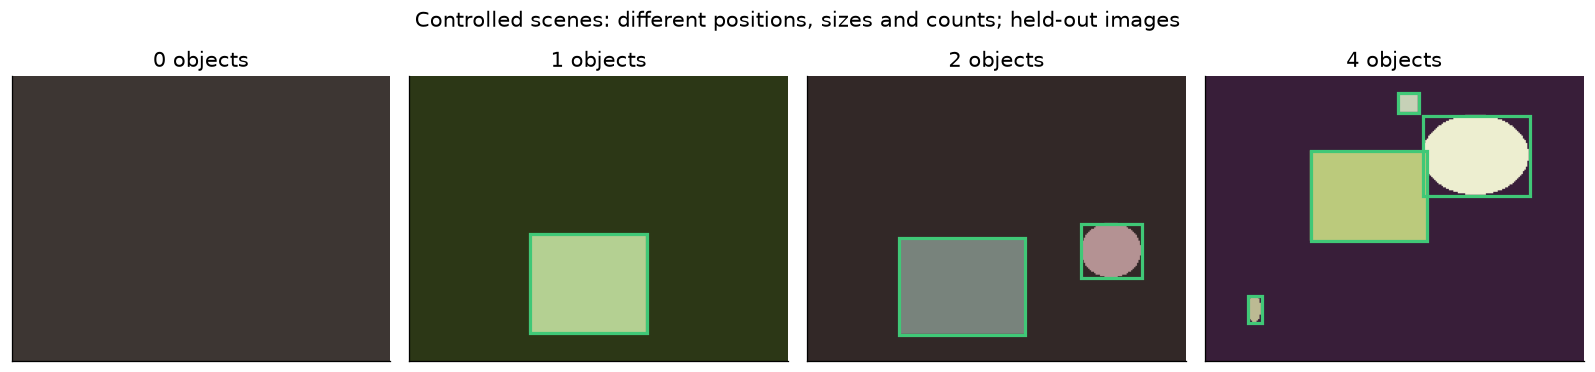

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
examples = [next(i for i in VALIDATION if not len(RECORDS[i]['boxes']))]
examples += [next(i for i in VALIDATION if len(RECORDS[i]['boxes']) == n) for n in (1, 2, 4)]
for ax, index in zip(axes, examples):
    show_image(ax, index)
    for box in RECORDS[index]['boxes']:
        draw_box(ax, index, box, '#40c877')
    ax.set_title(f'{len(RECORDS[index]["boxes"])} objects')
fig.suptitle('Controlled scenes: different positions, sizes and counts; held-out images')
fig.tight_layout()
finish_figure('00_dataset')


## 1. Что хранит query и как он читает изображение

У каждого кандидата есть три разные величины:

| Величина | Размер одного кандидата | Назначение |
|---|---|---|
| Состояние $q_i^{(t)}$ | $64$ | Собранные признаки; обновляется каждым слоем |
| Embedding $e_i$ (`query_position`) | $64$ | Обучаемый вектор, добавляемый в attention; одинаков для всех изображений |
| Бокс $b_i^{(t)}=(c_x,c_y,w,h)$ | $4$ | Явная геометрическая оценка в нормированных координатах |

$e_i$ не является парой $(x,y)$ и не вычисляется из бокса. Начальные $q_i^{(0)}$, $e_i$ и logits начального бокса — три отдельных набора параметров. Сначала центры боксов стоят на сетке $4\times8$, ширина равна 0.25, высота — 0.35; при обучении эти значения меняются.

После cross-attention $q_i$ содержит признаки конкретного изображения. Общая для кандидатов classification head отображает $64\to2$: объект / no-object. Box head отображает $64\to64\to4$ и предсказывает поправку к координатам. У каждого слоя своя box head; classification head общая и между слоями.

**Почему кандидаты могут находить разные объекты?** У них разные начальные параметры, они по-разному читают признаки, а matching назначает каждому GT только одного кандидата. Номер query не задаёт класс или постоянный номер объекта. Self-attention позволяет обмениваться состояниями, но само по себе не запрещает дубликаты.

Во всех вариантах оставляем эти компоненты одинаковыми. Сначала используем `GlobalRead`: чтение всех позиций C5. Отдельного spatial transformer encoder в этой реализации нет.

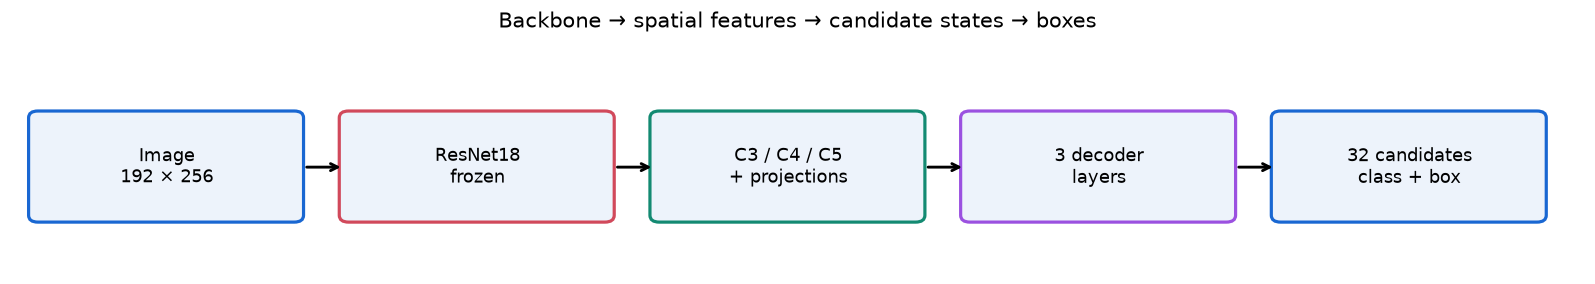

In [6]:
def pipeline(labels, name, title):
    fig, ax = plt.subplots(figsize=(14, 2.6))
    ax.set_xlim(-.12, len(labels) * 2)
    ax.set_ylim(0, 2)
    for i, label in enumerate(labels):
        x = i * 2
        ax.add_patch(patches.FancyBboxPatch((x + .05, .5), 1.65, .85, boxstyle='round,pad=.06',
                                           facecolor='#edf3fb', edgecolor=COLORS[i % 4], linewidth=2))
        ax.text(x + .88, .92, label, ha='center', va='center', fontsize=11)
        if i + 1 < len(labels):
            ax.annotate('', (x + 2.02, .92), (x + 1.76, .92), arrowprops={'arrowstyle': '->', 'lw': 1.8})
    ax.set_title(title, pad=10)
    ax.axis('off')
    fig.tight_layout()
    finish_figure(name)

pipeline(['Image\n192 × 256', 'ResNet18\nfrozen', 'C3 / C4 / C5\n+ projections', '3 decoder\nlayers', '32 candidates\nclass + box'],
         '01a_architecture', 'Backbone → spatial features → candidate states → boxes')


In [7]:
def position_grid(height, width, dim, device):
    y, x = torch.meshgrid((torch.arange(height, device=device) + .5) / height,
                          (torch.arange(width, device=device) + .5) / width, indexing='ij')
    frequencies = 10000 ** (torch.arange(dim // 4, device=device) / (dim // 4))
    x, y = 2 * math.pi * x[..., None] / frequencies, 2 * math.pi * y[..., None] / frequencies
    return torch.cat([x.sin(), x.cos(), y.sin(), y.cos()], -1).reshape(1, height * width, dim)



class GlobalRead(nn.Module):
    def __init__(self, dim=DIM, heads=HEADS):
        super().__init__()
        self.attention = nn.MultiheadAttention(dim, heads, batch_first=True, dropout=0)

    def forward(self, query, maps, reference, trace=False):
        feature = maps[-1]
        memory = feature.flatten(2).transpose(1, 2)
        position = position_grid(*feature.shape[-2:], query.shape[-1], query.device)
        output, weights = self.attention(query, memory + position, memory,
                                         need_weights=trace, average_attn_weights=False)
        details = {'attention': weights.detach(), 'shape': feature.shape[-2:]} if trace else {}
        return output, details


### Что вычисляет dense cross-attention

После self-attention обозначим вход модуля чтения как $z_i=\widetilde q_i+e_i$. Для одной головы:

$$
Q_h=zW_{Q,h},\qquad
K_h=(F_5+P)W_{K,h},\qquad
V_h=F_5W_{V,h},
$$
$$
A_h=\operatorname{softmax}_{\text{позиции}}
\left(\frac{Q_hK_h^\top}{\sqrt{16}}\right),
\qquad
u=\operatorname{concat}_{h=1}^{4}(A_hV_h)W_O.
$$

$F_5$ здесь развёрнута в последовательность из $6\cdot8=48$ векторов; $P$ — синусоидальное кодирование координат сетки. Смещения линейных слоёв в формулах опущены. Размеры $Q_h$: $B\times32\times16$, $K_h,V_h$: $B\times48\times16$, $A_h$: $B\times32\times48$.

Позиции добавлены в **ключи**, чтобы отличать одинаковые признаки в разных местах, но не добавлены в **значения**. Softmax нормирует 48 позиций отдельно для каждого query: два кандидата могут одновременно дать большой вес одной области.

Даже в первом слое веса $A_h$ зависят от изображения через ключи $K_h$. На рисунке — веса из самого вызова `MultiheadAttention`, усреднённые по четырём головам. Это веса, которыми действительно собирались значения в этом forward.

Внутри слоя три residual-обновления с LayerNorm: self-attention → cross-attention → FFN ($64\to128\to64$, GELU). Состояние между слоями сохраняется; каждый новый слой дополняет уже собранные признаки.

In [8]:
class DecoderLayer(nn.Module):
    def __init__(self, reader, dim=DIM, heads=HEADS):
        super().__init__()
        self.self_attention = nn.MultiheadAttention(dim, heads, batch_first=True, dropout=0)
        self.reader = reader
        self.ffn = nn.Sequential(nn.Linear(dim, dim * 2), nn.GELU(), nn.Linear(dim * 2, dim))
        self.norms = nn.ModuleList([nn.LayerNorm(dim) for _ in range(3)])

    def forward(self, state, query_position, maps, reference, trace=False):
        q = state + query_position
        update, _ = self.self_attention(q, q, state, need_weights=False)
        state = self.norms[0](state + update)
        update, details = self.reader(state + query_position, maps, reference, trace)
        state = self.norms[1](state + update)
        state = self.norms[2](state + self.ffn(state))
        return state, details



def inverse_sigmoid(value):
    return torch.logit(value.clamp(1e-5, 1 - 1e-5))



class DetectionModel(nn.Module):
    def __init__(self, reader_factory, feedback=False):
        super().__init__()
        self.feedback = feedback
        self.adapters = nn.ModuleList([nn.Sequential(nn.Conv2d(channels, DIM, 1), nn.GroupNorm(8, DIM))
                                       for channels in (128, 256, 512)])
        self.query_content = nn.Embedding(QUERIES, DIM)
        self.query_position = nn.Embedding(QUERIES, DIM)
        y, x = torch.meshgrid(torch.linspace(.125, .875, 4), torch.linspace(.0625, .9375, 8), indexing='ij')
        initial = torch.stack([x.flatten(), y.flatten(), torch.full((QUERIES,), .25),
                               torch.full((QUERIES,), .35)], -1)
        self.initial_boxes = nn.Parameter(inverse_sigmoid(initial))
        self.layers = nn.ModuleList([DecoderLayer(reader_factory()) for _ in range(LAYERS)])
        self.class_head = nn.Linear(DIM, 2)
        self.box_heads = nn.ModuleList([nn.Sequential(nn.Linear(DIM, DIM), nn.ReLU(), nn.Linear(DIM, 4))
                                        for _ in range(LAYERS)])
        for head in self.box_heads:
            nn.init.zeros_(head[-1].weight)
            nn.init.zeros_(head[-1].bias)

    def forward(self, features, trace=False):
        maps = [adapter(feature) for adapter, feature in zip(self.adapters, features)]
        batch = features[0].shape[0]
        state = self.query_content.weight[None].expand(batch, -1, -1)
        query_position = self.query_position.weight[None].expand(batch, -1, -1)
        initial = self.initial_boxes.sigmoid()[None].expand(batch, -1, -1)
        box_state = initial
        stages, traces = [], []
        for layer, box_head in zip(self.layers, self.box_heads):
            read_reference = box_state if self.feedback else initial
            state, details = layer(state, query_position, maps, read_reference, trace)
            boxes = (inverse_sigmoid(box_state) + box_head(state)).sigmoid()
            stages.append({'logits': self.class_head(state), 'boxes': boxes})
            if trace:
                details.update(reference=read_reference.detach(), before=box_state.detach(), after=boxes.detach())
                traces.append(details)
            box_state = boxes.detach()
        return {**stages[-1], 'stages': stages, 'traces': traces}


### Как назначается цель каждому кандидату

Для $N\le Q$ объектов выбираем разные query $\pi(1),\ldots,\pi(N)$, минимизируя суммарную цену:

$$
\pi^*=\arg\min_{\pi\ \text{инъективно}}\sum_{j=1}^{N}C_{\pi(j),j},
\qquad
C_{ij}=-2p_i(c_j)+5\|b_i-g_j\|_1-2\,\operatorname{GIoU}(b_i,g_j).
$$

$g_j$ — GT-бокс, $c_j$ — его класс, $p_i(c_j)$ — вероятность класса. Для L1 используем нормированные $(c_x,c_y,w,h)$; для GIoU переводим боксы в координаты углов. Hungarian algorithm выбирает назначение без градиента; затем loss дифференцируется по выбранным предсказаниям.

$$
\mathcal L^{(t)}
=2\mathcal L_{\rm CE}^{(t)}
+5\mathcal L_{\rm L1}^{(t)}
+2\mathcal L_{\rm GIoU}^{(t)},\qquad
\mathcal L=\frac13\sum_{t=1}^{3}\mathcal L^{(t)}.
$$

CE обучает все 32 слота: matched получают класс объекта, остальные — no-object с весом 0.1. L1 и $1-\mathrm{GIoU}$ считаются только для matched-пар. На каждом слое своё назначение: один GT может обучать разные query на разных стадиях.

В matching используется $-p$, в CE — $-\log p$. Первый выбирает дискретные пары; второй обучает уверенность, сильнее штрафуя очень малую вероятность правильного класса. Коэффициенты 2/5/2 задают баланс сигналов, а не следуют из геометрии. Формулы нормировки, пример GIoU и роль каждого слагаемого разобраны в дополнении.

In [9]:
def match_predictions(output, targets):
    matches = []
    with torch.no_grad():
        for logits, boxes, target in zip(output['logits'], output['boxes'], targets):
            if not len(target['boxes']):
                matches.append((torch.empty(0, dtype=torch.long), torch.empty(0, dtype=torch.long)))
                continue
            cost_class = -logits.softmax(-1)[:, target['labels']]
            cost_l1 = torch.cdist(boxes, target['boxes'], p=1)
            cost_giou = -generalized_box_iou(xyxy(boxes), xyxy(target['boxes']))
            row, col = linear_sum_assignment((2 * cost_class + 5 * cost_l1 + 2 * cost_giou).cpu())
            matches.append((torch.as_tensor(row), torch.as_tensor(col)))
    return matches



def stage_loss(output, targets):
    matches = match_predictions(output, targets)
    expected = torch.ones(output['logits'].shape[:2], dtype=torch.long, device=DEVICE)
    predicted_boxes, target_boxes = [], []
    for batch, (rows, cols) in enumerate(matches):
        expected[batch, rows] = targets[batch]['labels'][cols]
        predicted_boxes.append(output['boxes'][batch, rows])
        target_boxes.append(targets[batch]['boxes'][cols])
    class_loss = F.cross_entropy(output['logits'].transpose(1, 2), expected,
                                 weight=output['logits'].new_tensor([1., .1]))
    predicted_boxes, target_boxes = torch.cat(predicted_boxes), torch.cat(target_boxes)
    if not len(target_boxes):
        return 2 * class_loss + output['boxes'].sum() * 0
    l1 = F.l1_loss(predicted_boxes, target_boxes, reduction='sum') / len(target_boxes)
    giou = (1 - generalized_box_iou(xyxy(predicted_boxes), xyxy(target_boxes)).diag()).mean()
    return 2 * class_loss + 5 * l1 + 2 * giou



def detection_loss(outputs, targets):
    return torch.stack([stage_loss(stage, targets) for stage in outputs['stages']]).mean()


In [10]:
VARIANTS = {
    'global': {'reader': 'global', 'feedback': False},
    'fixed': {'reader': 'sampling', 'learned': False, 'feedback': False, 'multiscale': False},
    'learned': {'reader': 'sampling', 'learned': True, 'feedback': False, 'multiscale': False},
    'refine': {'reader': 'sampling', 'learned': True, 'feedback': True, 'multiscale': False},
    'multi': {'reader': 'sampling', 'learned': True, 'feedback': True, 'multiscale': True},
}



def make_model(variant, seed):
    cfg = VARIANTS[variant]
    seed_everything(seed)
    template = DetectionModel(GlobalRead, feedback=False)
    initial = copy.deepcopy(template.state_dict())
    seed_everything(seed)
    factory = GlobalRead if cfg['reader'] == 'global' else lambda: SamplingRead(cfg['learned'], cfg['multiscale'])
    model = DetectionModel(factory, cfg['feedback'])
    compatible = {key: value for key, value in initial.items()
                  if key in model.state_dict() and model.state_dict()[key].shape == value.shape}
    model.load_state_dict(compatible, strict=False)
    return model.to(DEVICE)



def coco_metrics(predictions, indices):
    images, annotations, detections = [], [], []
    for prediction, index in zip(predictions, indices):
        record = RECORDS[index]
        width, height = record['size']
        images.append({'id': record['id'], 'width': width, 'height': height})
        factor = torch.tensor([width, height, width, height])
        for box in xyxy(record['boxes']) * factor:
            x1, y1, x2, y2 = box.tolist()
            annotations.append({'id': len(annotations) + 1, 'image_id': record['id'], 'category_id': 1,
                                'bbox': [x1, y1, x2 - x1, y2 - y1], 'area': (x2 - x1) * (y2 - y1), 'iscrowd': 0})
        boxes = xyxy(prediction['boxes']).clamp(0, 1) * factor
        for box, score in zip(boxes, prediction['scores']):
            x1, y1, x2, y2 = box.tolist()
            if x2 > x1 and y2 > y1:
                detections.append({'image_id': record['id'], 'category_id': 1,
                                   'bbox': [x1, y1, x2 - x1, y2 - y1], 'score': float(score)})
    truth = COCO()
    truth.dataset = {'images': images, 'annotations': annotations, 'categories': [{'id': 1, 'name': 'person'}], 'info': {}}
    with contextlib.redirect_stdout(io.StringIO()):
        truth.createIndex()
        detected = truth.loadRes(detections)
        evaluator = COCOeval(truth, detected, 'bbox')
        evaluator.params.imgIds = [image['id'] for image in images]
        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()
    keys = ['AP', 'AP50', 'AP75', 'AP_small', 'AP_medium', 'AP_large']
    return {key: float(value) for key, value in zip(keys, evaluator.stats[:6])}



@torch.no_grad()
def predict(model, indices):
    model.eval()
    predictions = []
    for start in range(0, len(indices), BATCH_SIZE):
        batch = indices[start:start + BATCH_SIZE]
        output = model(feature_batch(batch))
        for boxes, logits in zip(output['boxes'].cpu(), output['logits'].cpu()):
            predictions.append({'boxes': boxes, 'scores': logits.softmax(-1)[:, 0]})
    return predictions



def run_signature(variant, seed, steps):
    objects = [DetectionModel, DecoderLayer, GlobalRead, stage_loss,
               match_predictions, detection_loss, make_model, position_grid, inverse_sigmoid]
    if VARIANTS[variant]['reader'] == 'sampling':
        objects += [SamplingRead, sample_feature_maps]
    source_parts = []
    for obj in objects:
        members = [obj.__init__, obj.forward] if inspect.isclass(obj) else [obj]
        source_parts.extend(inspect.getsource(member).strip() for member in members)
    source = '\n'.join(source_parts)
    config = {'variant': variant, 'seed': seed, 'steps': steps, 'batch': BATCH_SIZE, 'dim': DIM,
              'heads': HEADS, 'queries': QUERIES, 'layers': LAYERS, 'points': POINTS,
              'size': IMAGE_SIZE, 'lr': .0004, 'train_ids': [RECORDS[i]['id'] for i in TRAIN],
              'validation_ids': [RECORDS[i]['id'] for i in VALIDATION], 'variant_config': VARIANTS[variant]}
    return hashlib.sha256((source + json.dumps(config, sort_keys=True)).encode()).hexdigest()[:16], config



def train_variant(variant, seed, steps=TRAIN_STEPS):
    key, config = run_signature(variant, seed, steps)
    path = RUNS / f'{variant}_s{seed}_{key}.pt'
    model = make_model(variant, seed)
    if path.exists():
        saved = torch.load(path, map_location=DEVICE, weights_only=True)
        model.load_state_dict(saved['state'])
        return model.eval(), saved['report']
    seed_everything(seed + 1000)
    generator = torch.Generator().manual_seed(seed + 2000)
    optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=.0004, weight_decay=.0001)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, steps, eta_min=.00004)
    history, train_seconds = [], 0.
    for step in range(1, steps + 1):
        indices = [TRAIN[i] for i in torch.randint(len(TRAIN), (BATCH_SIZE,), generator=generator).tolist()]
        features, targets = feature_batch(indices), targets_for(indices)
        model.train()
        started = time.perf_counter()
        optimizer.zero_grad(set_to_none=True)
        loss = detection_loss(model(features), targets)
        if not torch.isfinite(loss):
            raise RuntimeError(f'Nonfinite loss: {variant}, seed={seed}, step={step}')
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), .5)
        optimizer.step()
        scheduler.step()
        train_seconds += time.perf_counter() - started
        if step % 100 == 0 or step == steps:
            metrics = coco_metrics(predict(model, VALIDATION), VALIDATION)
            history.append({'step': step, 'loss': float(loss.detach()), 'seconds': train_seconds, **metrics})
            print(f'{variant:7} seed={seed} step={step:4} AP50={metrics["AP50"]:.3f} AP75={metrics["AP75"]:.3f}', flush=True)
    report = {'config': config, 'signature': key, 'history': history, 'metrics': history[-1],
              'parameters': sum(p.numel() for p in model.parameters()),
              'trainable_parameters': sum(p.numel() for p in model.parameters() if p.requires_grad),
              'train_seconds': train_seconds}
    torch.save({'state': model.state_dict(), 'report': report}, path)
    path.with_suffix('.json').write_text(json.dumps(report, indent=2))
    return model.eval(), report


In [11]:
MODELS, REPORTS = {}, {}
for seed in SEEDS:
    MODELS['global', seed], REPORTS['global', seed] = train_variant('global', seed)
print('Global baseline ready')


Global baseline ready


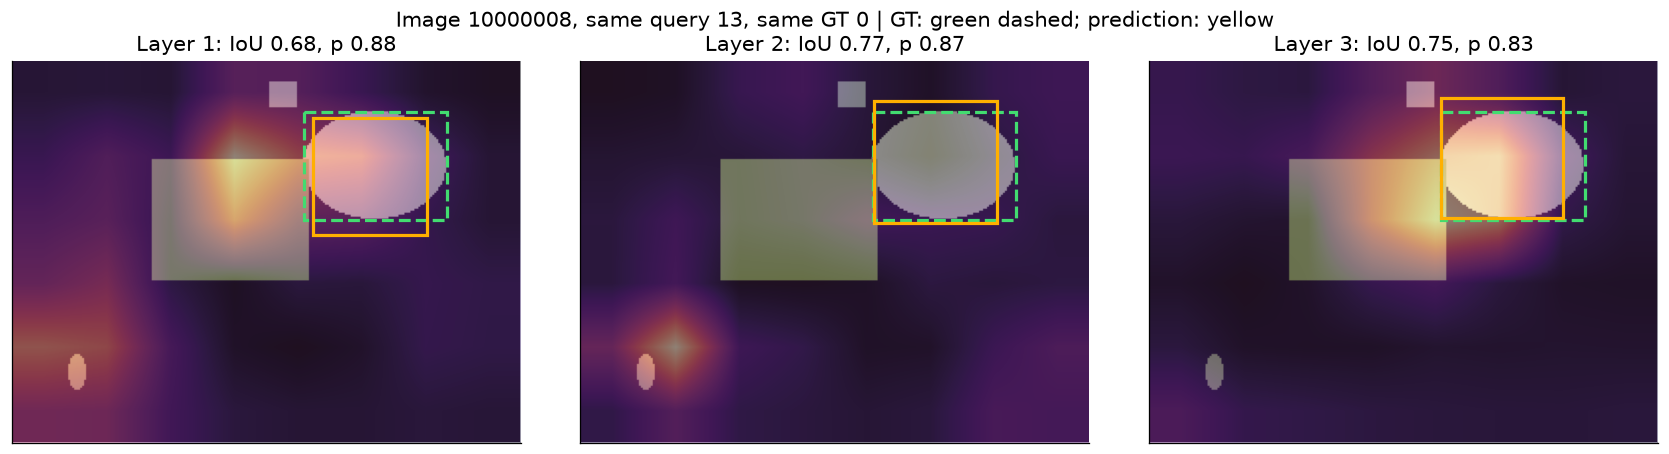

In [12]:
global_examples = matched_examples(MODELS['global', SEEDS[0]])
global_good = max(global_examples, key=lambda e: e['ious'][-1] * e['score'])
trajectory(MODELS['global', SEEDS[0]], global_good, '01b_global_attention')


На всех трёх панелях прослеживаем один query и один GT, назначенные **по последнему выходу**. Для этого кандидата IoU меняется $0.68\to0.77\to0.75$: чтение и бокс меняются, но улучшение не обязано быть монотонным.

Тепловая карта показывает, откуда пришли значения, жёлтый бокс — результат box head. Attention не является разметкой объекта: голова может использовать его части и окружающий контекст.

При увеличении разрешения плотное чтение требует больше сравнений. Следующий модуль заменяет матрицу сходств предсказанием нескольких координат и весов.

## 2. Как обучить координаты чтения

### Билинейная интерполяция

Округление координаты выбирает пиксель скачком: почти везде её производная равна нулю. Интерполяция делает прочитанное значение непрерывным по положению точки.

Пусть четыре соседних значения расположены так:

$$
\begin{array}{c|cc}
 & x=0 & x=1\\ \hline
y=0 & f_{00}=1 & f_{10}=3\\
y=1 & f_{01}=5 & f_{11}=7
\end{array}
$$

Внутри этой ячейки $x,y\in[0,1]$ измеряются от центра верхнего левого пикселя:

$$
f(x,y)=(1-x)(1-y)f_{00}+x(1-y)f_{10}
       +(1-x)y f_{01}+xy f_{11}.
$$
$$
f(x,y)=1+2x+4y,\quad
f(0.35,0.65)=4.3,\quad
\frac{\partial f}{\partial x}=2,\quad
\frac{\partial f}{\partial y}=4.
$$

Все четыре соседних значения получают градиент со своими коэффициентами. Координаты получают градиент через изменение этих коэффициентов.

**Три системы координат.** Для карты шириной $W$ центр пикселя с индексом $j$ имеет нормированную координату $p_x=(j+0.5)/W$. `grid_sample` при `align_corners=False` принимает $g_x=2p_x-1$. Обратное преобразование: $x_{\rm pixel}=Wp_x-0.5$. Для $y$ используем высоту $H$. Порядок координат в grid — $(x,y)$, форма карты — $(H,W)$.

Эти правила соответствуют [документации `grid_sample`](https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.grid_sample.html). Ошибка в половину ячейки особенно заметна на грубой карте.

[Численный перевод координат для карты 2×2](../ADDITIONAL_NOTES.md#coordinates).

In [13]:
values = torch.tensor([[[[1., 3.], [5., 7.]]]])
pixel_xy = torch.tensor([.35, .65], requires_grad=True)
normalized_xy = (pixel_xy + .5) / 2
grid = (2 * normalized_xy - 1).reshape(1, 1, 1, 2)
sample = F.grid_sample(values, grid, align_corners=False)
sample.sum().backward()
print(f'Value: {sample.item():.3f}; d(value)/d(x,y): {pixel_xy.grad.tolist()}')
assert torch.allclose(sample.squeeze(), torch.tensor(4.3))
assert torch.allclose(pixel_xy.grad, torch.tensor([2., 4.]))


Value: 4.300; d(value)/d(x,y): [2.0, 4.0]


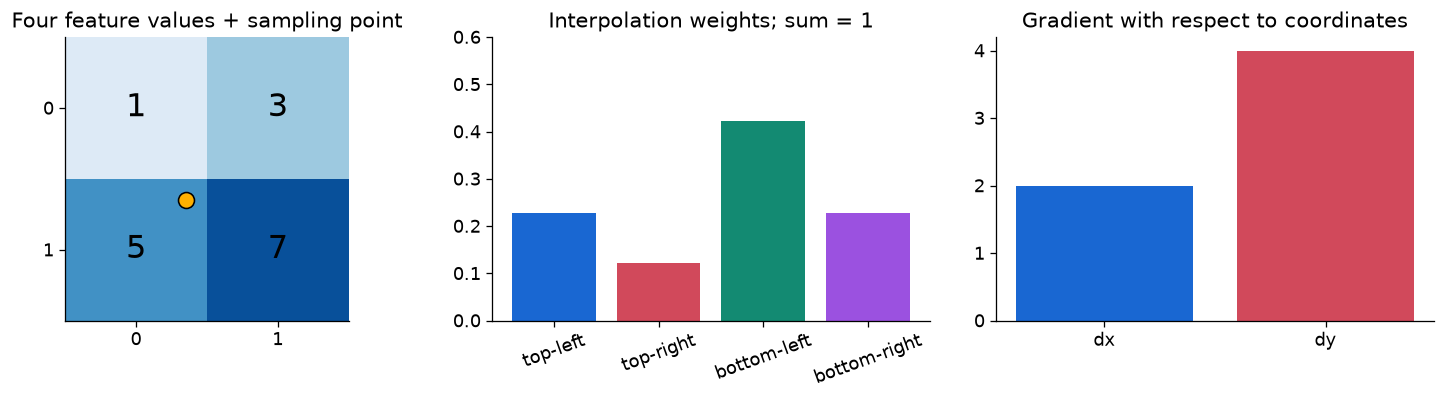

In [14]:
x, y = pixel_xy.detach().numpy()
mass = np.array([(1-x)*(1-y), x*(1-y), (1-x)*y, x*y])
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].imshow(values[0, 0], cmap='Blues', vmin=0, vmax=8)
for j in range(2):
    for i in range(2):
        axes[0].text(i, j, str(int(values[0, 0, j, i])), ha='center', va='center', fontsize=20)
axes[0].scatter(x, y, s=100, c='#ffb000', edgecolors='black')
axes[0].set_title('Four feature values + sampling point')
axes[0].set_xticks([0, 1]); axes[0].set_yticks([0, 1])
axes[1].bar(['top-left', 'top-right', 'bottom-left', 'bottom-right'], mass, color=COLORS)
axes[1].tick_params(axis='x', rotation=20)
axes[1].set_ylim(0, .6); axes[1].set_title('Interpolation weights; sum = 1')
axes[2].bar(['dx', 'dy'], pixel_xy.grad.numpy(), color=COLORS[:2])
axes[2].set_title('Gradient with respect to coordinates')
fig.tight_layout()
finish_figure('02a_interpolation')


Для произвольных четырёх значений координатные производные равны:

$$
\frac{\partial f}{\partial x}
 =(1-y)(f_{10}-f_{00})+y(f_{11}-f_{01}),\qquad
\frac{\partial f}{\partial y}
 =(1-x)(f_{01}-f_{00})+x(f_{11}-f_{10}).
$$

Поэтому в однородной области градиент по координатам равен нулю: небольшое движение не меняет прочитанный признак. На границах ячеек производная может скачком меняться. Далеко вне карты с zero padding прочитанное значение и координатный градиент также равны нулю.

### Query предсказывает, где читать и сколько взять

Вход reader — $z_i=\widetilde q_i+e_i$, опорный бокс — $r_i=(c_x,c_y,w,h)$. Для каждого query и каждой головы:

$$
\Delta_i=\operatorname{reshape}(z_iW_\Delta+\beta_\Delta),\qquad
a_{ihk}=\operatorname{softmax}_{k=1,\ldots,6}(z_iW_a+\beta_a)_{hk},
$$
$$
p_{ihk}=(c_x,c_y)+\tfrac12(w,h)\odot\Delta_{ihk},
$$
$$
u_i=\operatorname{concat}_{h=1}^{4}
\left[\sum_{k=1}^{6}a_{ihk}\,
\operatorname{Bilinear}\!\left(V_{\ell(k),h},p_{ihk}\right)\right]W_O.
$$

$h$ — номер головы; $k$ — номер точки; $\ell(k)$ — уровень признаков для этой точки. В этом блоке все точки читают C5. Проекция $V_\ell=F_\ell W_V$ по каналам имеет 64 канала; каждая голова читает свои 16. Bias value/output projections в записи опущены.

| Тензор | Размер |
|---|---|
| Смещения $\Delta$, координаты $p$ | $B\times32\times4\times6\times2$ |
| Веса точек $a$ | $B\times32\times4\times6$ |
| Результат $u$ | $B\times32\times64$ |

Голова смещений выдаёт $4\cdot6\cdot2=48$ чисел, голова весов — $4\cdot6=24$. Здесь **нет сравнения query с ключами каждого пикселя**: и точки, и веса получаем непосредственно из $z_i$. Не путать шесть обучаемых весов $a_k$ с четырьмя коэффициентами интерполяции внутри каждой точки.

Смещение $(1,0)$ означает чтение на правой границе опорного бокса; $(2,0)$ — уже за ней. Смещения не ограничены sigmoid или clipping. Бокс задаёт систему координат, а не жёсткую границу области чтения.

Для одной прочитанной компоненты на карте шириной $W_\ell$:

$$
\frac{\partial\mathcal L}{\partial\Delta_x}
=\frac{\partial\mathcal L}{\partial f}\,
 \frac{\partial f}{\partial x_{\rm pixel}}\,
 W_\ell\frac{w}{2}.
$$

Так detection loss обучает координаты без разметки самих точек. При суммировании каналов и точек складываются соответствующие градиенты.

[Шесть точек и разделение 64 каналов между головами](../ADDITIONAL_NOTES.md#points-and-heads).

In [15]:
def sample_feature_maps(maps, locations, weights, level_ids):
    batch, queries, heads, points, _ = locations.shape
    head_dim = maps[0].shape[1] // heads
    result = maps[0].new_zeros(batch, heads, head_dim, queries)
    for level in sorted(set(level_ids)):
        slots = [i for i, value in enumerate(level_ids) if value == level]
        feature = maps[level]
        height, width = feature.shape[-2:]
        values = feature.reshape(batch * heads, head_dim, height, width)
        grid = locations[:, :, :, slots].permute(0, 2, 1, 3, 4).reshape(batch * heads, queries, len(slots), 2)
        sampled = F.grid_sample(values, 2 * grid - 1, mode='bilinear', padding_mode='zeros', align_corners=False)
        sampled = sampled.reshape(batch, heads, head_dim, queries, len(slots))
        mass = weights[:, :, :, slots].permute(0, 2, 1, 3).unsqueeze(2)
        result = result + (sampled * mass).sum(-1)
    return result.permute(0, 3, 1, 2).reshape(batch, queries, heads * head_dim)



class SamplingRead(nn.Module):
    def __init__(self, learned=True, multiscale=False, dim=DIM, heads=HEADS, points=POINTS):
        super().__init__()
        self.heads, self.points = heads, points
        self.level_ids = [i % 3 if multiscale else 2 for i in range(points)]
        self.offsets = nn.Linear(dim, heads * points * 2)
        self.weights = nn.Linear(dim, heads * points)
        self.value_projection = nn.Conv2d(dim, dim, 1)
        self.output_projection = nn.Linear(dim, dim)
        angle = torch.arange(heads) * 2 * math.pi / heads
        direction = torch.stack([angle.cos(), angle.sin()], -1)
        pattern = direction[:, None] * torch.linspace(1 / points, 1, points)[None, :, None]
        nn.init.zeros_(self.offsets.weight)
        with torch.no_grad():
            self.offsets.bias.copy_(pattern.flatten())
        nn.init.zeros_(self.weights.weight)
        nn.init.zeros_(self.weights.bias)
        self.offsets.requires_grad_(learned)

    def forward(self, query, maps, reference, trace=False):
        batch, queries, _ = query.shape
        offsets = self.offsets(query).reshape(batch, queries, self.heads, self.points, 2)
        weights = self.weights(query).reshape(batch, queries, self.heads, self.points).softmax(-1)
        locations = reference[:, :, None, None, :2] + .5 * reference[:, :, None, None, 2:] * offsets
        values = [self.value_projection(feature) for feature in maps]
        output = sample_feature_maps(values, locations, weights, self.level_ids)
        details = {'locations': locations.detach(), 'weights': weights.detach(),
                   'level_ids': list(self.level_ids)} if trace else {}
        return self.output_projection(output), details


### Инициализация и первая абляция

В начале матрица $W_\Delta=0$, а bias задаёт четыре направления — по одному на голову. Шесть точек лежат на расстояниях $1/6,\ldots,1$ в координатах смещений. Веса равны $1/6$. Такой старт распределяет точки вокруг центра; если сразу вынести их далеко за изображение, zero padding может лишить координаты полезного градиента.

| Вариант | Голова смещений | Что продолжает учиться |
|---|---|---|
| `fixed` | Заморожена в начальном состоянии | Веса точек, проекции, queries, начальные боксы, heads |
| `learned` | Обучается | Те же параметры |

Начальные значения всех параметров в паре совпадают. **Фиксируются относительные смещения**, но начальные боксы продолжают меняться при обучении. В `fixed` нет обратной связи от предсказанного бокса, поэтому после обучения координаты точек одинаковы для разных изображений и всех трёх слоёв; различаются признаки и веса чтения.

В `learned` первый набор координат тоже одинаков для разных изображений: вход первого reader ещё не содержит признаков изображения. Со второго слоя $z_i$ уже зависит от предыдущего чтения. Проверка ниже сравнивает координаты на двух изображениях: для первого слоя разность ровно ноль, для следующих — ненулевая.

На Shapes итоговый AP50: `fixed` $0.217\pm0.007$, `learned` $0.213\pm0.016$. При 600 шагах размораживание смещений не дало прироста. Обучаемость операции и выигрыш метрики — разные проверяемые утверждения.

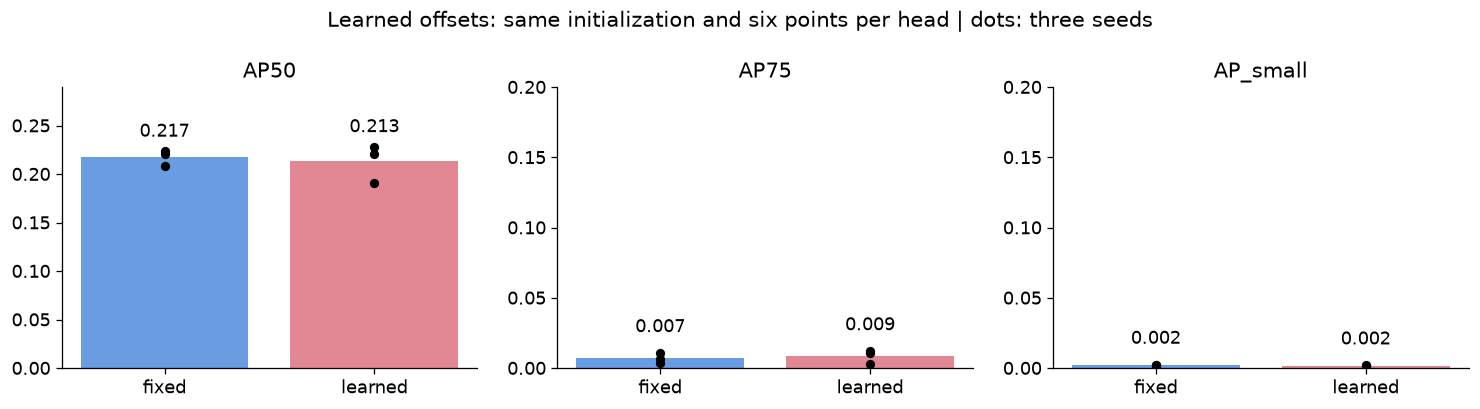

In [16]:
for variant in ('fixed', 'learned'):
    for seed in SEEDS:
        MODELS[variant, seed], REPORTS[variant, seed] = train_variant(variant, seed)
compare_pair('fixed', 'learned', 'Learned offsets: same initialization and six points per head', '02b_offsets_ablation')


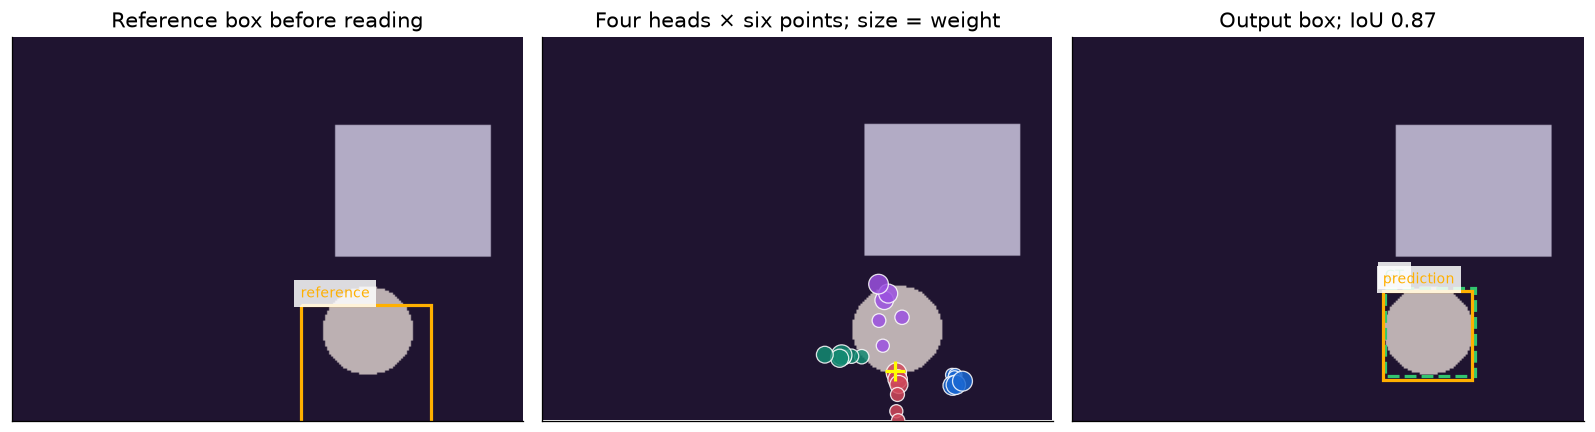

Layer 1: mean coordinate difference between two images = 0.000000
Layer 2: mean coordinate difference between two images = 0.006087
Layer 3: mean coordinate difference between two images = 0.008094


In [17]:
learned_examples = matched_examples(MODELS['learned', SEEDS[0]])
learned_good = max(learned_examples, key=lambda e: e['ious'][-1] * e['score'])
index, query = learned_good['index'], learned_good['query']
with torch.no_grad():
    output = MODELS['learned', SEEDS[0]](feature_batch([index]), trace=True)
detail = output['traces'][-1]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
show_image(axes[0], index)
draw_box(axes[0], index, detail['reference'][0, query], '#ffb000', 'reference')
axes[0].set_title('Reference box before reading')
show_image(axes[1], index); draw_sampling(axes[1], index, detail, query)
axes[1].set_title('Four heads × six points; size = weight')
show_image(axes[2], index)
draw_box(axes[2], index, RECORDS[index]['boxes'][learned_good['gt']], '#32c66f', 'GT', '--')
draw_box(axes[2], index, output['boxes'][0, query].cpu(), '#ffb000', 'prediction')
axes[2].set_title(f'Output box; IoU {learned_good["ious"][-1]:.2f}')
fig.tight_layout(); finish_figure('02c_learned_points')
empty_index = next(i for i in VALIDATION if not len(RECORDS[i]['boxes']))
with torch.no_grad():
    pair = MODELS['learned', SEEDS[0]](feature_batch([index, empty_index]), trace=True)
for layer, details in enumerate(pair['traces']):
    difference = (details['locations'][0] - details['locations'][1]).abs().mean().item()
    print(f'Layer {layer + 1}: mean coordinate difference between two images = {difference:.6f}')
assert torch.equal(pair['traces'][0]['locations'][0], pair['traces'][0]['locations'][1])


## 3. Зачем возвращать предсказанный бокс в attention

Состояние $q_i^{(t)}$ уже хранит признаки, но в `learned` область чтения по-прежнему привязана к исходному боксу $b_i^{(0)}$. Если кандидат нашёл объект в другом месте или другого размера, следующий слой может использовать эту геометрическую оценку напрямую.

### Уточнение в пространстве logits

$$
\delta_i^{(t)}=\operatorname{MLP}_t(q_i^{(t)}),\qquad
b_i^{(t)}=\sigma\!\left(
\operatorname{logit}(b_i^{(t-1)})+\delta_i^{(t)}\right).
$$

Операции покомпонентные для $(c_x,c_y,w,h)$. Нулевая поправка сохраняет предыдущий бокс; ненулевая меняет его, оставляя компоненты в $(0,1)$. Последний линейный слой каждой box head инициализирован нулями, поэтому до обучения все стадии сохраняют начальные боксы.

Для одной компоненты $b=0.2$ и $\delta=\ln2$:

$$
b'=\sigma(\operatorname{logit}(0.2)+\ln2)=\tfrac13,\qquad
\frac{b'}{1-b'}=e^\delta\frac{b}{1-b}.
$$

Поправка умножает отношение $b/(1-b)$, а не добавляет постоянный сдвиг в пикселях. Производная $\partial b'/\partial\delta=b'(1-b')$ уменьшается около 0 и 1. Перед `logit` код ограничивает вход диапазоном $[10^{-5},1-10^{-5}]$ для численной устойчивости. Центр и размер в $(0,1)$ не гарантируют, что углы бокса находятся внутри изображения.

### Что меняет абляция

Формула уточнения используется **в обоих** вариантах. Меняется только опорный бокс $r_i^{(t)}$, относительно которого считаются точки:

$$
\texttt{learned}:\ r_i^{(t)}=b_i^{(0)},\qquad
\texttt{refine}:\ r_i^{(t)}=b_i^{(t-1)}.
$$

```python
read_reference = box_state if self.feedback else initial
state, details = layer(state, query_position, maps, read_reference, trace)
boxes = (inverse_sigmoid(box_state) + box_head(state)).sigmoid()
box_state = boxes.detach()
```

`detach` сохраняет значения координат, но убирает путь градиента через них к предыдущей стадии. Путь через состояние query остаётся: поздний loss по-прежнему обучает ранние decoder layers. Промежуточные losses дают прямой сигнал каждой box head; без них ранние box heads не получили бы сигнал через отсоединённые боксы.

Чтение теперь зависит от двух результатов предыдущего слоя: **признаки в $q$ определяют смещения и веса; бокс задаёт центр и масштаб**.

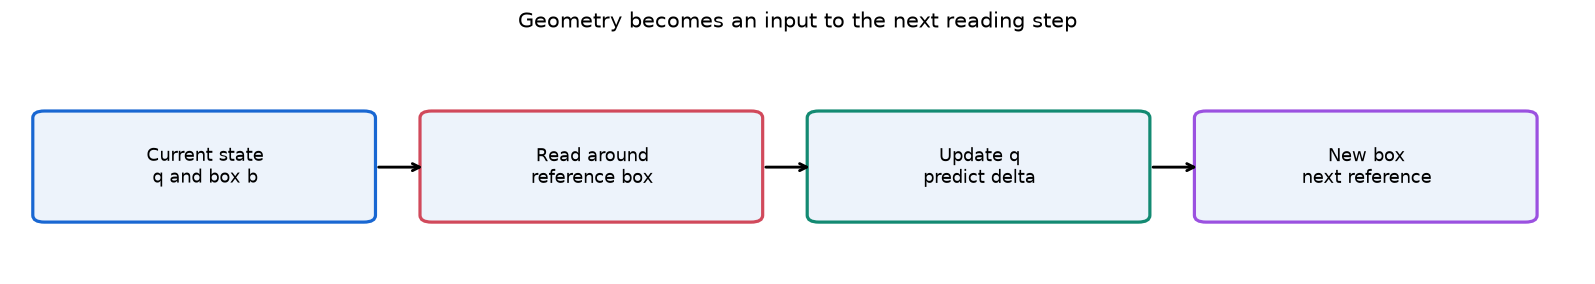

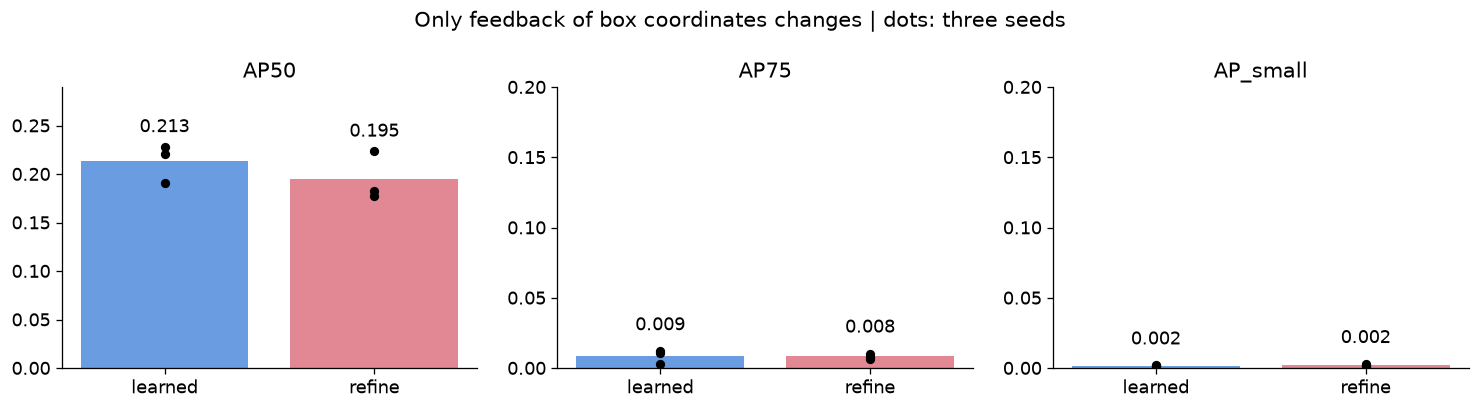

In [18]:
pipeline(['Current state\nq and box b', 'Read around\nreference box', 'Update q\npredict delta', 'New box\nnext reference'],
         '03a_feedback', 'Geometry becomes an input to the next reading step')
for seed in SEEDS:
    MODELS['refine', seed], REPORTS['refine', seed] = train_variant('refine', seed)
compare_pair('learned', 'refine', 'Only feedback of box coordinates changes', '03b_feedback_ablation')


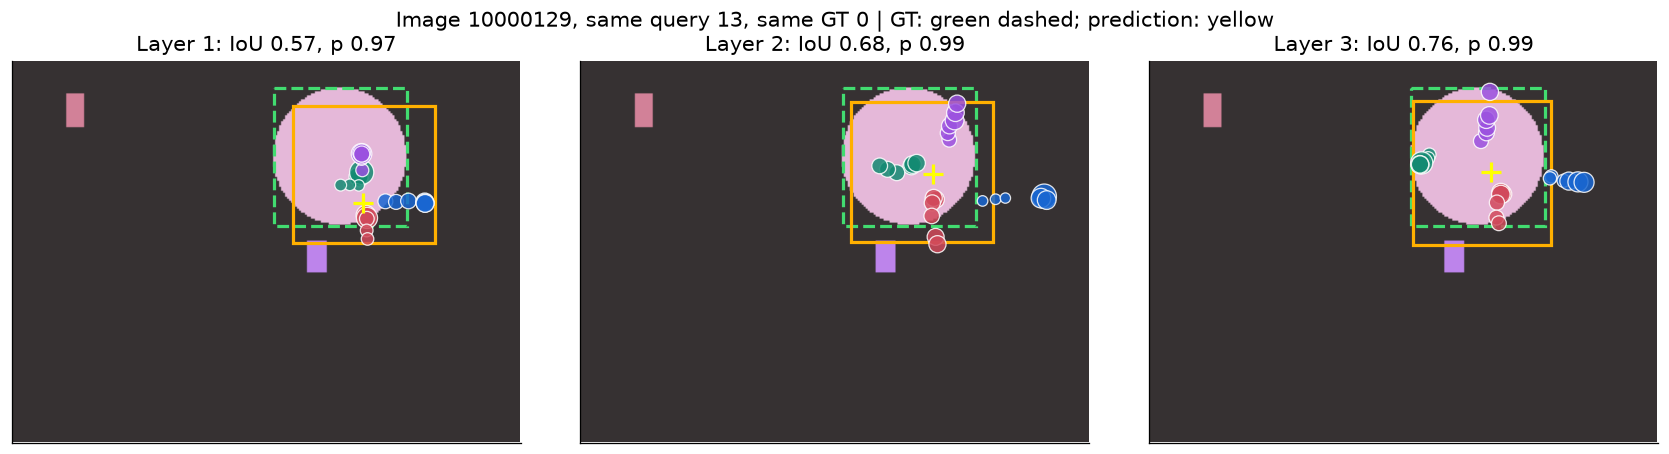

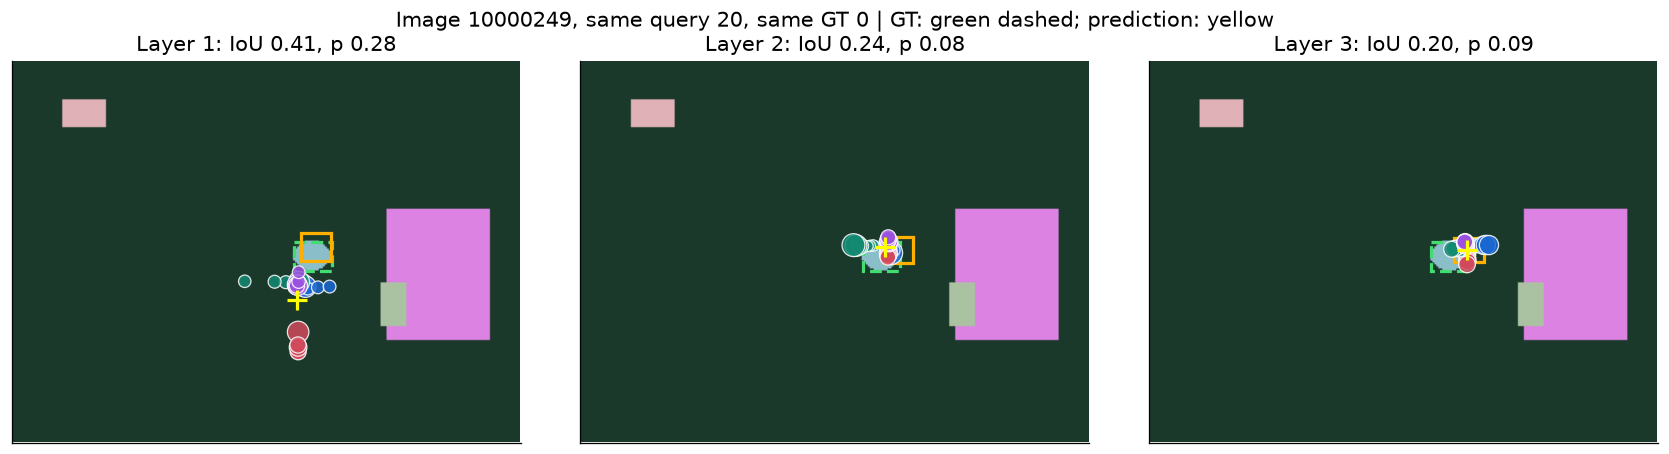

In [19]:
refine_examples = matched_examples(MODELS['refine', SEEDS[0]])
confident_examples = [e for e in refine_examples if e['ious'][-1] >= .5 and e['score'] >= .3]
refine_good = max(confident_examples, key=lambda e: e['ious'][-1] - e['ious'][0])
refine_bad = min(refine_examples, key=lambda e: e['ious'][-1] - e['ious'][0])
trajectory(MODELS['refine', SEEDS[0]], refine_good, '03c_refinement_good')
trajectory(MODELS['refine', SEEDS[0]], refine_bad, '03d_refinement_error')


В удачном примере IoU одного кандидата растёт $0.57\to0.68\to0.76$, а $p(\mathrm{object})$ — $0.97\to0.99\to0.99$. В примере ошибки IoU падает $0.41\to0.24\to0.20$, вероятность — $0.28\to0.20\to0.09$.

Обновлённая геометрия меняет следующее чтение. Ошибка бокса может увести точки в другую область; полезного сигнала в состоянии станет меньше. Loss каждого слоя требует хорошего предсказания, но не содержит условия $\operatorname{IoU}_{t+1}\ge\operatorname{IoU}_t$.

Оба ряда сохраняют один query и один GT по matching последнего слоя. Первый выбран по наибольшему росту среди кандидатов с финальными IoU ≥ 0.5 и $p(\mathrm{object})$ ≥ 0.3, второй — по наибольшему падению среди всех matched-кандидатов validation.

Средний AP50 всей выборки: `learned` $0.213\pm0.016$, `refine` $0.195\pm0.021$. Удачная траектория показывает возможное поведение; она не доказывает улучшения модели в целом.

## 4. Зачем нужны признаки нескольких разрешений

Объект шириной 12 пикселей занимает:

| Уровень | Шаг | Ширина объекта в ячейках |
|---|---:|---:|
| C3 | 8 | $12/8=1.5$ |
| C4 | 16 | $12/16=0.75$ |
| C5 | 32 | $12/32=0.375$ |

CNN может закодировать маленький объект в каналах C5, даже если он занимает меньше ячейки. Но отдельной подробной сетки внутри объекта уже нет. Билинейная интерполяция смешивает имеющиеся значения и не восстанавливает утраченное пространственное разрешение.

Одинаковая нормированная точка $p_x$ читается на уровне $\ell$ в координате $x_\ell=W_\ell p_x-0.5$. Поэтому для разных уровней не требуется предсказывать координаты в пикселях: меняется разрешение карты, система координат изображения общая.

### Абляция с постоянным числом точек

`refine`: $\ell(k)=[C5,C5,C5,C5,C5,C5]$.

`multi`: $\ell(k)=[C3,C4,C5,C3,C4,C5]$.

На каждой голове остаётся шесть точек — по две на уровень в `multi`. Размер голов смещений и весов, все начальные параметры и обновление боксов совпадают. Уровень каждой точки назначен кодом; модель обучает её координаты и вес.

$$
\sum_{k=1}^{6}a_{ihk}=1,\qquad
m_{ih\ell}=\sum_{k:\ell(k)=\ell}a_{ihk},
\qquad \sum_\ell m_{ih\ell}=1.
$$

$m_{ih\ell}$ — суммарный вес уровня в одной голове. **Две точки на уровень не означают треть веса:** все шесть logits входят в один softmax. На рисунке показано среднее $m_{ih\ell}$ по головам выбранного query.

У уровней отдельные входные проекции в 64 канала и общая value projection внутри reader. Top-down FPN здесь нет: признаки C3/C4/C5 объединяются при чтении в состояние query.

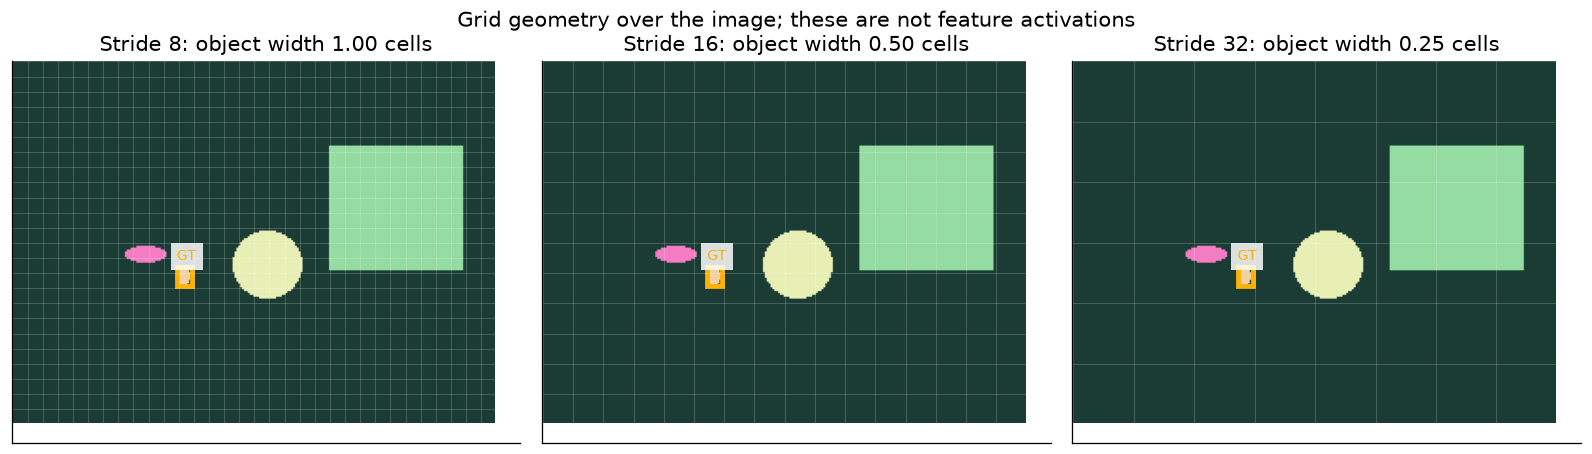

In [20]:
small_example = min((e for e in refine_examples), key=lambda e: float(RECORDS[e['index']]['boxes'][e['gt'], 2:].prod()))
index, gt = small_example['index'], small_example['gt']
box = RECORDS[index]['boxes'][gt]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, stride in zip(axes, (8, 16, 32)):
    show_image(ax, index)
    draw_box(ax, index, box, '#ffb000', 'GT', linewidth=3)
    for x in range(0, IMAGE_SIZE[1] + 1, stride): ax.axvline(x, color='white', alpha=.2, lw=.6)
    for y in range(0, IMAGE_SIZE[0] + 1, stride): ax.axhline(y, color='white', alpha=.2, lw=.6)
    ax.set_title(f'Stride {stride}: object width {float(box[2]) * IMAGE_SIZE[1] / stride:.2f} cells')
fig.suptitle('Grid geometry over the image; these are not feature activations')
fig.tight_layout(); finish_figure('04a_small_object_grids')


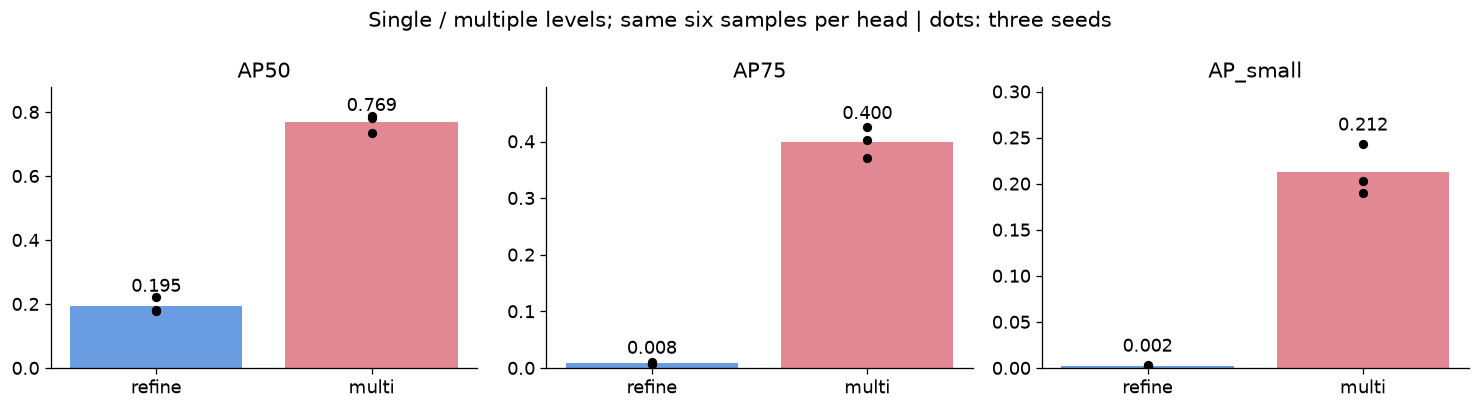

In [21]:
for seed in SEEDS:
    MODELS['multi', seed], REPORTS['multi', seed] = train_variant('multi', seed)
compare_pair('refine', 'multi', 'Single / multiple levels; same six samples per head', '04b_scales_ablation')


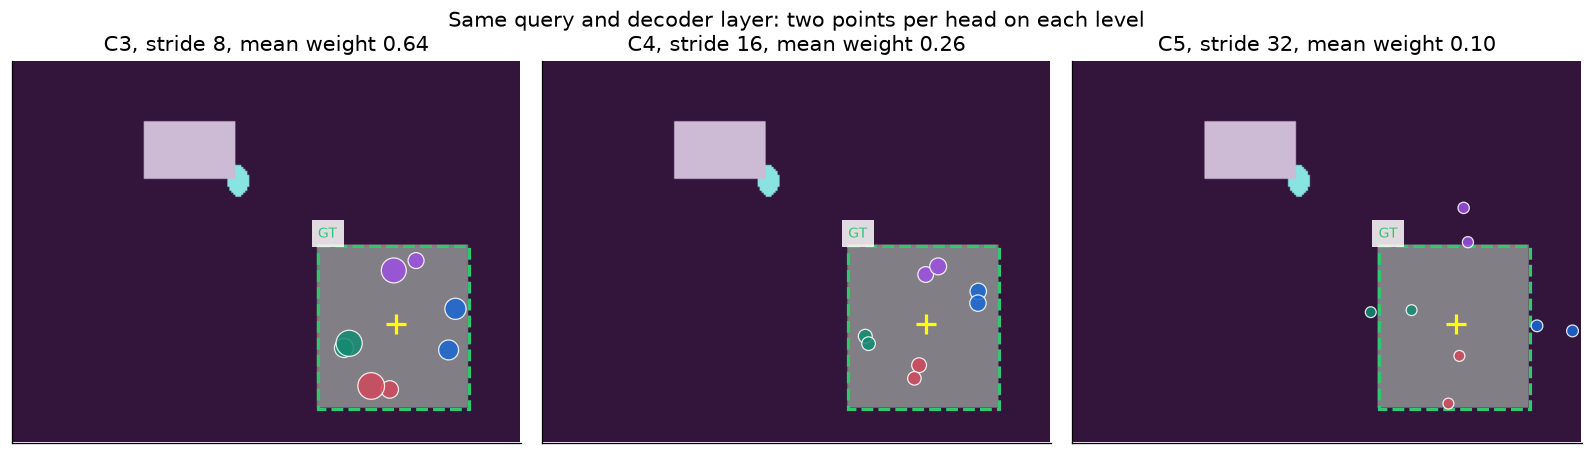

In [22]:
multi_examples = matched_examples(MODELS['multi', SEEDS[0]])
multi_good = max(multi_examples, key=lambda e: e['ious'][-1] * e['score'])
index, query = multi_good['index'], multi_good['query']
with torch.no_grad():
    output = MODELS['multi', SEEDS[0]](feature_batch([index]), trace=True)
detail = output['traces'][-1]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for level, ax in enumerate(axes):
    show_image(ax, index)
    draw_box(ax, index, RECORDS[index]['boxes'][multi_good['gt']], '#32c66f', 'GT', '--')
    draw_sampling(ax, index, detail, query, level=level)
    slots = [i for i, value in enumerate(detail['level_ids']) if value == level]
    mass = float(detail['weights'][0, query, :, slots].sum(-1).mean())
    ax.set_title(f'C{level + 3}, stride {2 ** (level + 3)}, mean weight {mass:.2f}')
fig.suptitle('Same query and decoder layer: two points per head on each level')
fig.tight_layout(); finish_figure('04c_multiscale_points')


## 5. Что изменилось в качестве и вычислениях

| Пара | Единственное изменение в парном опыте | AP50 на Shapes |
|---|---|---:|
| `fixed → learned` | Размораживание головы смещений | $0.217\to0.213$ |
| `learned → refine` | Обновлённый бокс задаёт координаты следующего чтения | $0.213\to0.195$ |
| `refine → multi` | Источники шести точек: C5 → C3/C4/C5 | $0.195\to0.769$ |

Для каждого seed в паре совпадают начальные значения параметров, split и последовательность batch. При размораживании смещений меняется число **обучаемых** параметров; в двух остальных парах оно одинаково. `global / sampling` меняет целиком reader и его параметры, поэтому это отдельное сравнение архитектур.

Оцениваем последний checkpoint после 600 шагов. В таблице среднее и стандартное отклонение по трём seeds; это разброс от инициализации и порядка batch, а не доверительный интервал по новым изображениям.

### Что означают метрики

**AP50** требует IoU ≥ 0.50, **AP75** — IoU ≥ 0.75. При каждой границе предсказания ранжируются по уверенности; повторная детекция уже найденного GT считается false positive. Поэтому хороший бокс с низкой уверенностью и несколько дубликатов могут ухудшить AP.

**AP** усредняет AP при десяти IoU-порогах $0.50,0.55,\ldots,0.95$. **AP_small** использует ту же сетку IoU-порогов для объектов площадью до $32^2$ пикселей в исходном изображении; граница medium/large — $96^2$.

В COCOeval передаём все 32 кандидата, без NMS и порога уверенности. Порог 0.3 нужен только для рисунков. Matching в обучении и сопоставление для AP — разные процедуры: AP использует ранжированные предсказания при заданном IoU-пороге.

In [23]:
def report_table(reports, title):
    from IPython.display import HTML, display
    columns = ['AP', 'AP50', 'AP75', 'AP_small', 'AP_medium', 'AP_large']
    rows = []
    for variant in VARIANTS:
        values = []
        for metric in columns:
            scores = np.array([reports[variant, seed]['metrics'][metric] for seed in SEEDS])
            values.append(f'{scores.mean():.3f} ± {scores.std():.3f}')
        rows.append('<tr><td>' + variant + '</td><td>' + '</td><td>'.join(values) + '</td></tr>')
    display(HTML('<b>' + title + '</b><table><tr><th>variant</th>' + ''.join('<th>' + c + '</th>' for c in columns)
                 + '</tr>' + ''.join(rows) + '</table>'))

report_table(REPORTS, 'Shapes, validation: mean ± standard deviation across three seeds')
summary = [REPORTS[variant, seed] for variant in VARIANTS for seed in SEEDS]
(RUNS / 'shapes_results.json').write_text(json.dumps(summary, indent=2))


variant,AP,AP50,AP75,AP_small,AP_medium,AP_large
global,0.003 ± 0.001,0.011 ± 0.004,0.000 ± 0.000,0.000 ± 0.000,0.006 ± 0.003,-1.000 ± 0.000
fixed,0.056 ± 0.002,0.217 ± 0.007,0.007 ± 0.003,0.002 ± 0.000,0.133 ± 0.003,-1.000 ± 0.000
learned,0.060 ± 0.003,0.213 ± 0.016,0.009 ± 0.004,0.002 ± 0.000,0.144 ± 0.007,-1.000 ± 0.000
refine,0.055 ± 0.002,0.195 ± 0.021,0.008 ± 0.002,0.002 ± 0.001,0.141 ± 0.010,-1.000 ± 0.000
multi,0.408 ± 0.019,0.769 ± 0.024,0.400 ± 0.022,0.212 ± 0.022,0.625 ± 0.024,-1.000 ± 0.000


113018

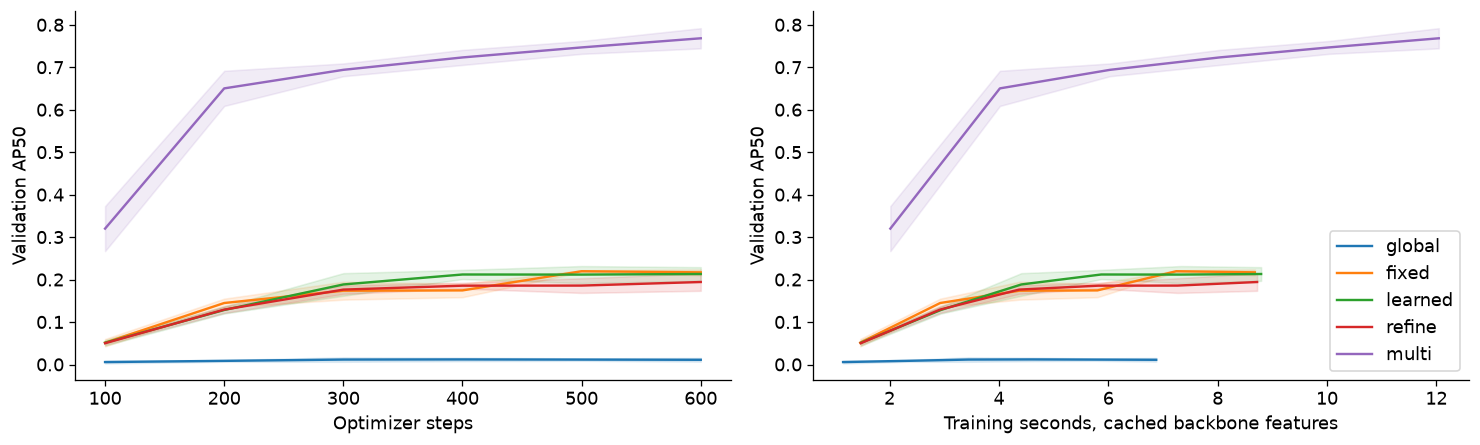

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
palette = plt.get_cmap('tab10')
for color, variant in enumerate(VARIANTS):
    histories = [REPORTS[variant, seed]['history'] for seed in SEEDS]
    steps = [item['step'] for item in histories[0]]
    scores = np.array([[item['AP50'] for item in history] for history in histories])
    times = np.array([[item['seconds'] for item in history] for history in histories])
    for ax, x in zip(axes, [np.array(steps), times.mean(0)]):
        ax.plot(x, scores.mean(0), label=variant, color=palette(color))
        ax.fill_between(x, scores.mean(0) - scores.std(0), scores.mean(0) + scores.std(0), color=palette(color), alpha=.12)
        ax.set_ylabel('Validation AP50')
axes[0].set_xlabel('Optimizer steps'); axes[1].set_xlabel('Training seconds, cached backbone features')
axes[1].legend(); fig.tight_layout(); finish_figure('05a_learning_curves')


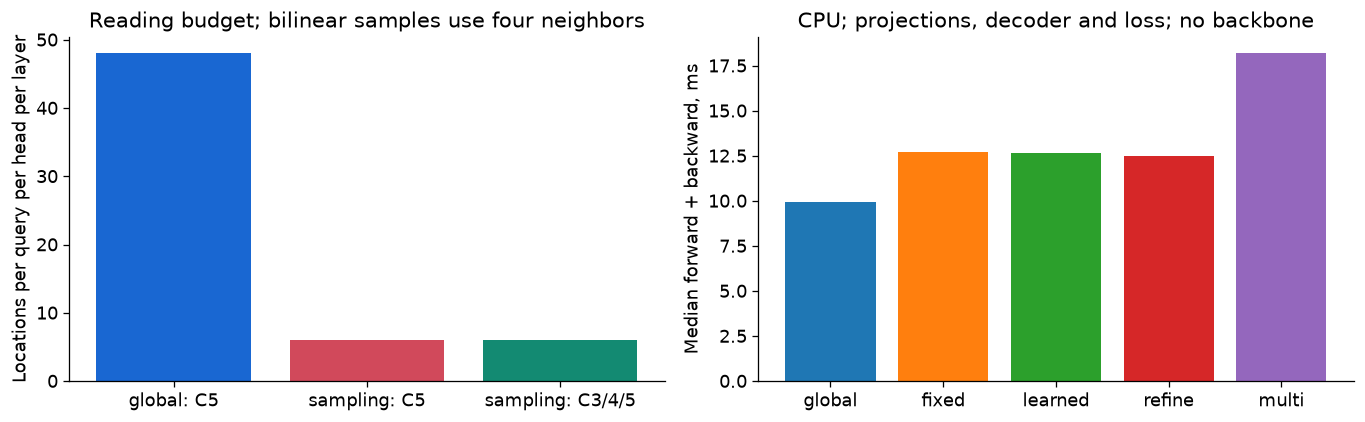

160

In [25]:
def benchmark(model, repeats=15):
    batch = feature_batch(TRAIN[:BATCH_SIZE])
    targets = targets_for(TRAIN[:BATCH_SIZE])
    timings = []
    for i in range(repeats + 3):
        model.zero_grad(set_to_none=True)
        start = time.perf_counter()
        detection_loss(model(batch), targets).backward()
        if i >= 3:
            timings.append(1000 * (time.perf_counter() - start))
    model.zero_grad(set_to_none=True)
    return float(np.median(timings))

timings = {variant: benchmark(MODELS[variant, SEEDS[0]]) for variant in VARIANTS}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(['global: C5', 'sampling: C5', 'sampling: C3/4/5'], [48, 6, 6], color=COLORS[:3])
axes[0].set_ylabel('Locations per query per head per layer')
axes[0].set_title('Reading budget; bilinear samples use four neighbors')
axes[1].bar(list(timings), list(timings.values()), color=plt.get_cmap('tab10').colors[:5])
axes[1].set_ylabel('Median forward + backward, ms')
axes[1].set_title('CPU; projections, decoder and loss; no backbone')
fig.tight_layout(); finish_figure('05b_compute')
(RUNS / 'benchmark.json').write_text(json.dumps(timings, indent=2))


### Число чтений и время

Для одной головы dense attention хранит $Q S$ весов, где $S=H_\ell W_\ell$. Sampling предсказывает $QK$ весов:

$$
C5:\quad QS=32\cdot48=1536,\qquad
QK=32\cdot6=192.
$$

Если плотное чтение охватывает все три уровня, $S=24\cdot32+12\cdot16+6\cdot8=1008$. Sampling по-прежнему использует шесть точек на голову. Число членов взвешенной суммы не растёт вместе с разрешением, но вычислить и спроецировать сами карты всё равно нужно.

Это не оценка полного FLOP count: одна билинейная точка использует четырёх соседей, остаются проекции, self-attention queries и FFN. В сохранённом CPU-замере dense reader даёт около 10 ms, sampling C5 — 12.5–12.7 ms, multi — 18.2 ms. На маленьком C5 матричные операции эффективнее нескольких вызовов `grid_sample`.

Измерено время forward + backward проекций, декодера и loss: batch 8, четыре CPU-потока, медиана 15 повторений после трёх прогревов. Backbone заранее вычислен; optimizer step в замер не входит. Пространственный encoder с его $S\times S$ attention отсутствует во всех вариантах.

### Проверка на реальных изображениях

COCO128 содержит 128 изображений из COCO train2017 с YOLO-разметкой. Оставляем person и изображения без людей: в train 96 изображений и 184 человека, в validation — 32 изображения и 70 человек. Это собственный split; crowd-разметки в исходном YOLO-формате нет.

Все пять декодеров обучаются заново с тремя seeds. Изображения растягиваются до $192\times256$, backbone заморожен, аугментаций нет. Предсказания перед оценкой переводятся в пиксели исходного изображения, поэтому пороги площади small/medium/large считаются до resize. Эти числа не являются результатом на COCO val2017.

In [26]:
SHAPES_REPORTS = REPORTS
SHAPES_MODELS = MODELS
SHAPES_DATA = (RECORDS, TRAIN, VALIDATION, FEATURES)
RECORDS = load_records()
TRAIN, VALIDATION = split_records(RECORDS)
FEATURES = cache_features(RECORDS)
REAL_MODELS, REAL_REPORTS = {}, {}
for variant in VARIANTS:
    for seed in SEEDS:
        REAL_MODELS[variant, seed], REAL_REPORTS[variant, seed] = train_variant(variant, seed)
report_table(REAL_REPORTS, 'COCO128/person, own split: mean ± standard deviation')
(RUNS / 'coco128_results.json').write_text(json.dumps(list(REAL_REPORTS.values()), indent=2))


variant,AP,AP50,AP75,AP_small,AP_medium,AP_large
global,0.005 ± 0.004,0.010 ± 0.007,0.007 ± 0.005,0.000 ± 0.000,0.000 ± 0.000,0.018 ± 0.011
fixed,0.003 ± 0.001,0.007 ± 0.002,0.002 ± 0.002,0.000 ± 0.000,0.001 ± 0.001,0.022 ± 0.019
learned,0.003 ± 0.002,0.007 ± 0.003,0.002 ± 0.003,0.000 ± 0.000,0.001 ± 0.001,0.012 ± 0.010
refine,0.004 ± 0.003,0.014 ± 0.010,0.002 ± 0.003,0.000 ± 0.000,0.001 ± 0.001,0.015 ± 0.012
multi,0.008 ± 0.007,0.023 ± 0.005,0.007 ± 0.009,0.000 ± 0.000,0.002 ± 0.003,0.026 ± 0.022


67849

На Shapes переход `refine → multi` поднял AP50 с 0.195 до 0.769, AP75 — с 0.008 до 0.400, AP_small — с 0.002 до 0.212. В этой постановке чтение только C5 заметно ограничивало локализацию; обучение смещений и обратная связь при том же грубом источнике такого эффекта не дали.

По этим опытам нельзя отдельно приписать весь прирост **разрешению сетки**: C3, C4 и C5 отличаются также глубиной и признаками. Абляция проверяет добавление уровней целиком. Для отделения разрешения от содержания понадобился бы отдельный контроль с изменением разрешения одной и той же карты.

На COCO128 средний validation AP50 находится в диапазоне 0.007–0.023. У `multi`, seed 41, train AP50 = 0.286, validation AP50 = 0.015. Модель частично подогналась под train, но плохо обобщает. По этим данным нельзя выбрать одну причину: одновременно ограничены число примеров, длительность обучения, разрешение и возможность адаптировать backbone.

Ниже — траектория одного query, предсказания при $p\ge0.3$ и train/validation одного checkpoint. Последний график помогает отделить способность подогнать обучение от качества на новых изображениях.

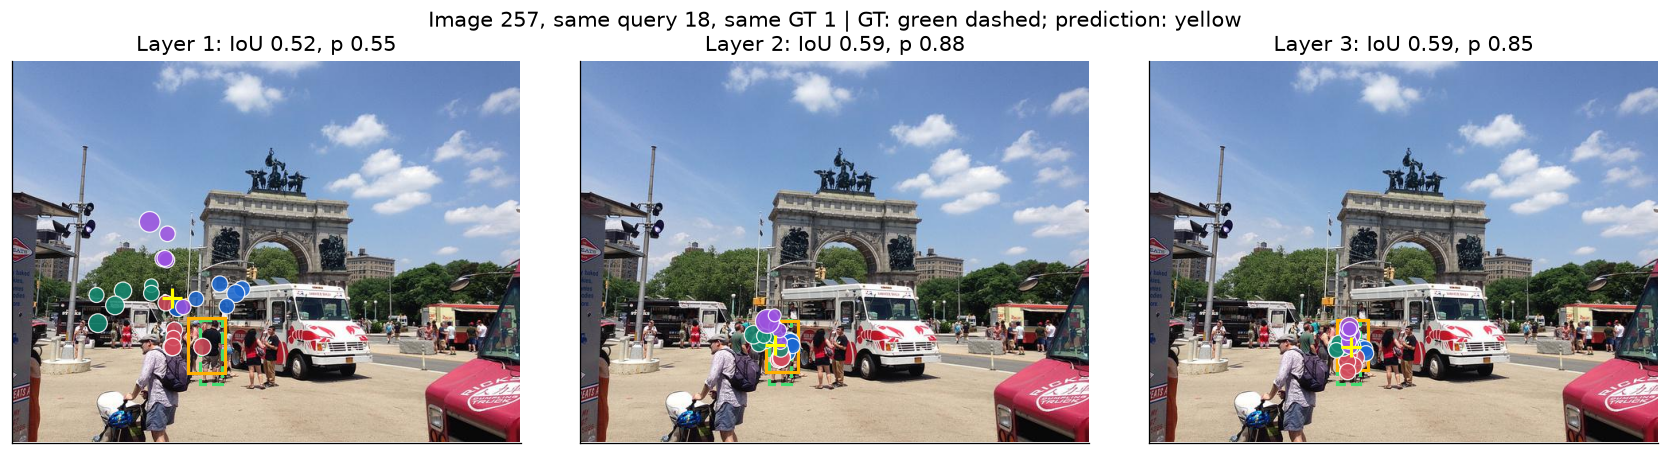

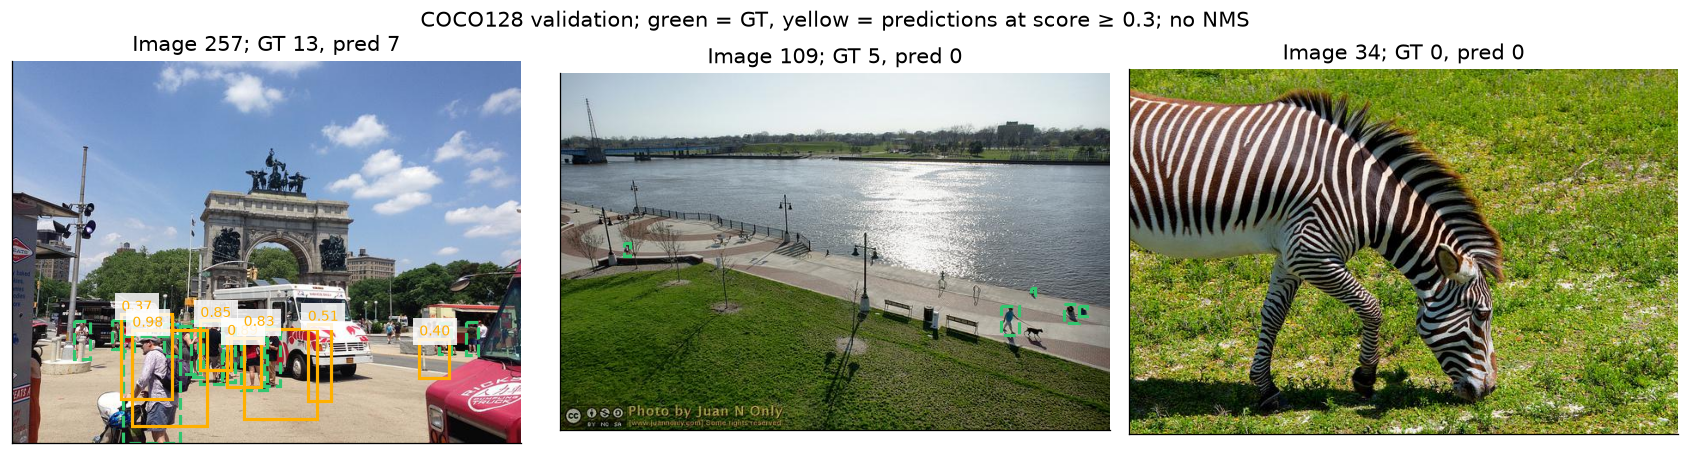

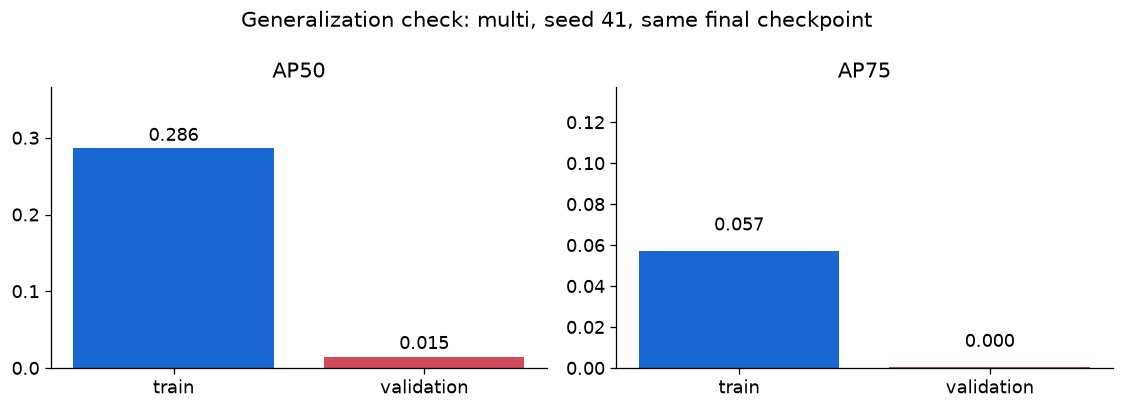

In [27]:
real_model = REAL_MODELS['multi', SEEDS[0]]
real_examples = matched_examples(real_model)
real_good = max(real_examples, key=lambda e: e['ious'][-1] * e['score'])
real_bad = min(real_examples, key=lambda e: e['ious'][-1])
trajectory(real_model, real_good, '05c_real_trajectory')
empty_index = next(i for i in VALIDATION if not len(RECORDS[i]['boxes']))
selected = [real_good['index'], real_bad['index'], empty_index]
predictions = predict(real_model, selected)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, index, prediction in zip(axes, selected, predictions):
    show_image(ax, index)
    for box in RECORDS[index]['boxes']:
        draw_box(ax, index, box, '#32c66f', style='--')
    keep = prediction['scores'] >= .3
    for box, score in zip(prediction['boxes'][keep], prediction['scores'][keep]):
        draw_box(ax, index, box, '#ffb000', f'{score:.2f}')
    ax.set_title(f'Image {RECORDS[index]["id"]}; GT {len(RECORDS[index]["boxes"])}, pred {int(keep.sum())}')
fig.suptitle('COCO128 validation; green = GT, yellow = predictions at score ≥ 0.3; no NMS')
fig.tight_layout(); finish_figure('05d_real_predictions')

train_metrics = coco_metrics(predict(real_model, TRAIN), TRAIN)
validation_metrics = REAL_REPORTS['multi', SEEDS[0]]['metrics']
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, metric in zip(axes, ['AP50', 'AP75']):
    values = [train_metrics[metric], validation_metrics[metric]]
    ax.bar(['train', 'validation'], values, color=COLORS[:2])
    for x, value in enumerate(values): ax.text(x, value + .01, f'{value:.3f}', ha='center')
    ax.set_title(metric); ax.set_ylim(0, max(values) + .08)
fig.suptitle('Generalization check: multi, seed 41, same final checkpoint')
fig.tight_layout(); finish_figure('05e_train_validation')


### Итоговая модель

$$
\text{RGB}\ \longrightarrow\ \text{ResNet18}\ \longrightarrow\
\{F_3,F_4,F_5\}
$$
$$
\begin{aligned}
q^{(t-1)}
&\xrightarrow{\ \text{self-attention}\ }\ \widetilde q
\xrightarrow[\ b^{(t-1)},F_3,F_4,F_5\ ]{\ \text{sampling}\ }\ q'
\xrightarrow{\ \text{FFN}\ }\ q^{(t)},\\
q^{(t)}
&\xrightarrow{\ \text{class / box heads}\ }\ (p^{(t)},b^{(t)}).
\end{aligned}
$$

Три слоя поддерживают два состояния: вектор признаков $q$ и бокс $b$. Query задаёт смещения и веса, бокс — центр и масштаб чтения. Каждая из четырёх голов получает шесть интерполированных значений, по два с C3/C4/C5. Предсказанный бокс используется на следующем слое с остановкой градиента по координатам. Обучение: one-to-one matching и CE + L1 + GIoU на каждой стадии; inference берёт последнюю стадию без NMS.

Получился небольшой **декодер с multi-scale deformable attention и iterative box refinement**, построенный по принципам Deformable DETR. Здесь 32 queries, learned initial boxes, один класс и замороженный ResNet18; encoder, proposal generator и специализированный CUDA sampling kernel не реализованы.

В [официальном модуле Deformable DETR](https://github.com/fundamentalvision/Deformable-DETR/blob/main/models/ops/modules/ms_deform_attn.py) число sampling points задаётся **на каждый уровень**. Здесь шесть точек — общий бюджет головы по всем уровням: так сравнение C5 / C3+C4+C5 не увеличивает число чтений.

## Дополнение. L1, GIoU и нормировка loss

### Почему одной ошибки координат недостаточно

L1 непосредственно измеряет расстояние между нормированными $(c_x,c_y,w,h)$:

$$
\|b-g\|_1=|c_x-\hat c_x|+|c_y-\hat c_y|+|w-\hat w|+|h-\hat h|.
$$

Но одинаковый сдвиг по-разному влияет на маленький и большой объект. У двух одинаковых боксов ширины $w$, сдвинутых по $x$ на $d<w$, при одинаковой вертикальной координате:

$$
\operatorname{IoU}=\frac{(w-d)h}{(w+d)h}=\frac{w-d}{w+d}.
$$

При $d=0.02$ ошибка центра L1 одинакова. Для $w=0.10$ IoU = $2/3$, для $w=0.50$ IoU = $12/13\approx0.923$. Перекрытие учитывает ошибку относительно размера объекта.

### Что добавляет GIoU

Для предсказанного прямоугольника $R$, GT $G$ и минимального охватывающего прямоугольника $C$:

$$
\operatorname{IoU}(R,G)=\frac{|R\cap G|}{|R\cup G|},\qquad
\operatorname{GIoU}(R,G)=\operatorname{IoU}(R,G)
-\frac{|C|-|R\cup G|}{|C|}.
$$

Когда боксы не пересекаются, IoU равен нулю в целой области координат и не указывает направление сближения. GIoU штрафует незаполненную часть охватывающего прямоугольника. Это не заменяет L1: например, при вложенных боксах $C=R\cup G$ добавка GIoU равна нулю, а L1 продолжает напрямую штрафовать координаты.

Для $R=[0,0,1,1]$ и $G=[d,0,d+1,1]$, $d>1$:

$$
\operatorname{IoU}=0,\qquad
\operatorname{GIoU}=-\frac{d-1}{d+1}.
$$

При $d=1.1,2,10$ получаем $-0.048,-0.333,-0.818$. Ошибочная замена штрафа на $1-\operatorname{IoU}$ дала бы $2\operatorname{IoU}-1=-1$ во всех трёх случаях и потеряла бы расстояние между непересекающимися боксами.

In [28]:
reference = torch.tensor([[0., 0., 1., 1.]])
distances = [1.1, 2., 10.]
for x in distances:
    other = torch.tensor([[x, 0., x + 1., 1.]])
    iou = box_iou(reference, other).item()
    giou = generalized_box_iou(reference, other).item()
    print(f'Other box x={x:4}: IoU={iou:.3f}; GIoU={giou:.3f}')


Other box x= 1.1: IoU=0.000; GIoU=-0.048
Other box x= 2.0: IoU=0.000; GIoU=-0.333
Other box x=10.0: IoU=0.000; GIoU=-0.818


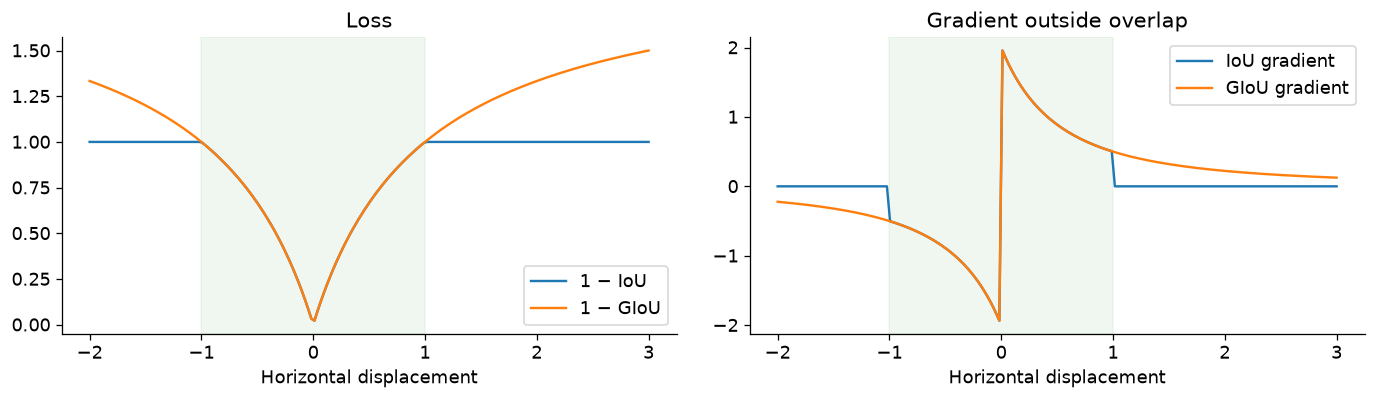

In [29]:
positions = torch.linspace(-2, 3, 180)
iou_values, giou_values, iou_gradients, giou_gradients = [], [], [], []
for position in positions:
    x = position.detach().clone().requires_grad_(True)
    candidate = torch.stack([x, x * 0, x + 1, x * 0 + 1])[None]
    iou_loss = 1 - box_iou(candidate, reference)[0, 0]
    giou_loss = 1 - generalized_box_iou(candidate, reference)[0, 0]
    iou_gradients.append(float(torch.autograd.grad(iou_loss, x, retain_graph=True)[0]))
    giou_gradients.append(float(torch.autograd.grad(giou_loss, x)[0]))
    iou_values.append(float(iou_loss.detach())); giou_values.append(float(giou_loss.detach()))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(positions, iou_values, label='1 − IoU'); axes[0].plot(positions, giou_values, label='1 − GIoU')
axes[1].plot(positions, iou_gradients, label='IoU gradient'); axes[1].plot(positions, giou_gradients, label='GIoU gradient')
for ax in axes:
    ax.axvspan(-1, 1, color='green', alpha=.06); ax.set_xlabel('Horizontal displacement'); ax.legend()
axes[0].set_title('Loss'); axes[1].set_title('Gradient outside overlap')
fig.tight_layout(); finish_figure('a01_giou')


### Точные нормировки и роль no-object

Пусть $y_{bi}$ — класс, назначенный query $i$ изображения $b$, $n$ — число GT во всём batch. Вес foreground $\alpha_0=1$, no-object $\alpha_\varnothing=0.1$. Используемая в коде weighted mean cross-entropy:

$$
\mathcal L_{\rm CE}
=\frac{\sum_{b=1}^{B}\sum_{i=1}^{Q}
 \alpha_{y_{bi}}\big[-\log p_{bi}(y_{bi})\big]}
 {\sum_{b=1}^{B}\sum_{i=1}^{Q}\alpha_{y_{bi}}}.
$$

Знаменатель — сумма весов назначенных классов, а не $BQ$. Например, для одного изображения с двумя GT: вес положительных слагаемых $2$, остальных $30\cdot0.1=3$, знаменатель $5$. Даже после downweighting фон остаётся существенной частью loss.

Если весь batch пустой, все веса одинаковы и 0.1 сокращается в числителе и знаменателе. Поэтому в этой реализации empty batch не получает автоматически в десять раз меньший CE. На пустых изображениях боксы не обучаются, но queries получают сигнал no-object.

Для $n>0$ и множества matched-пар $\mathcal M$:

$$
\mathcal L_{\rm L1}
=\frac1n\sum_{(i,j)\in\mathcal M}\|b_i-g_j\|_1,\qquad
\mathcal L_{\rm GIoU}
=\frac1n\sum_{(i,j)\in\mathcal M}
\left[1-\operatorname{GIoU}(b_i,g_j)\right].
$$

L1 суммирует четыре координаты и делит на число объектов; среднего по четырём координатам здесь нет. При $n=0$ обе box-составляющие равны нулю. Полный loss усредняет три стадии с одинаковыми весами.

No-object обучает свободные слоты подавлять лишние предсказания. One-to-one matching создаёт этот сигнал, но не гарантирует отсутствие дубликатов при inference. Каждый дубликат может ухудшить AP; NMS в этих опытах не используется.

### Проверки вычислений

Следующая ячейка проверяет градиенты билинейного чтения, совпадение начальных параметров парных вариантов, нормировку весов, пустые targets и AP идеальных предсказаний.

In [30]:
first = make_model('fixed', 41)
for left, right in [('fixed', 'learned'), ('learned', 'refine'), ('refine', 'multi')]:
    a, b = make_model(left, 41), make_model(right, 41)
    assert all(torch.equal(value, b.state_dict()[key]) for key, value in a.state_dict().items())

values = torch.randn(1, 8, 4, 6, dtype=torch.double, requires_grad=True)
locations = torch.tensor([[[[[.43, .41], [.62, .67]], [[.36, .37], [.71, .61]]]]], dtype=torch.double, requires_grad=True)
weights = torch.full((1, 1, 2, 2), .5, dtype=torch.double, requires_grad=True)
assert torch.autograd.gradcheck(lambda a, b, c: sample_feature_maps([a], b, c, [0, 0]), (values, locations, weights))

truth = [{'boxes': RECORDS[i]['boxes'], 'scores': torch.ones(len(RECORDS[i]['boxes']))} for i in VALIDATION]
assert abs(coco_metrics(truth, VALIDATION)['AP'] - 1) < 1e-6
sample_output = REAL_MODELS['multi', 41](feature_batch(VALIDATION[:2]), trace=True)
empty = [{'boxes': torch.empty(0, 4), 'labels': torch.empty(0, dtype=torch.long)} for _ in range(2)]
assert torch.isfinite(detection_loss(sample_output, empty))
for detail in sample_output['traces']:
    assert torch.allclose(detail['weights'].sum(-1), torch.ones_like(detail['weights'][..., 0]))
print('Passed: paired initialization, coordinate gradients, perfect AP, empty targets, attention normalization')


Passed: paired initialization, coordinate gradients, perfect AP, empty targets, attention normalization


### Источники

- [DETR](https://arxiv.org/abs/2005.12872): предсказание множества объектов, bipartite matching.
- [Deformable DETR](https://arxiv.org/abs/2010.04159): sparse multi-scale attention и уточнение боксов.
- [Официальный модуль attention](https://github.com/fundamentalvision/Deformable-DETR/blob/main/models/ops/modules/ms_deform_attn.py), [реализация sampling на PyTorch](https://github.com/fundamentalvision/Deformable-DETR/blob/main/models/ops/functions/ms_deform_attn_func.py), [декодер с refinement](https://github.com/fundamentalvision/Deformable-DETR/blob/main/models/deformable_transformer.py).
- [PyTorch: `grid_sample`](https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.grid_sample.html), [weighted cross-entropy](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html).
- [GIoU](https://arxiv.org/abs/1902.09630), [COCOeval](https://github.com/cocodataset/cocoapi/blob/master/PythonAPI/pycocotools/cocoeval.py).
- [Исходный семинар ШАДа](https://github.com/yandexdataschool/deep_vision_and_graphics/tree/fall25/week05-object_detection/seminar).
- [COCO128](https://github.com/ultralytics/assets/releases/download/v0.0.0/coco128.zip): изображения COCO и YOLO-разметка. Авторские права на фотографии принадлежат их авторам; идентификаторы сохранены на рисунках.